# 🌵 Predicción de sequía meteorológica en el Altiplano boliviano
**Proyecto de Análisis de Datos** · preprocesamiento → EDA → outliers → modelos → evaluación → (despliegue)

**Pregunta:** dadas las condiciones climáticas hasta el mes *t*, ¿habrá condición de sequía (SPI-3 ≤ −1) en el mes *t+h*, con *h* = 1, 2, 3?

**Fuentes (públicas):** NASA POWER (precipitación corregida, temperatura, humedad, viento, presión, radiación; diario) y NOAA/CPC ONI (índice de El Niño).

**Cómo está organizado este cuaderno**

| Parte | Contenido |
|---|---|
| 1–3 | Adquisición, descripción detallada y limpieza |
| 4 | Análisis exploratorio (EDA) |
| 5 | Outliers: IQR, MAD e Isolation Forest |
| 6 | SPI y variable objetivo |
| 7 | Ingeniería de variables y particiones temporales |
| 8–11 | Líneas base, comparación de modelos, efecto de outliers, ajuste de hiperparámetros |
| 12–17 | Evaluación final, horizontes, errores, interpretabilidad, caso 2016, temporada lluviosa |
| 18 | Guardado del modelo para el despliegue |

> ⚠️ Los resultados dependen de los datos descargados. Si ves un aviso rojo de **MODO SINTÉTICO**, los datos son simulados (solo prueba de instalación) y **no deben usarse en el informe**.

In [1]:
import os, sys, warnings, datetime as dt
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
from src import config as C, datos, spi as S, features as F, modelos as M, pipeline as P, predecir as PR

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "figure.autolayout": False})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170); pd.set_option("display.precision", 3)

def guardar(nombre):
    plt.savefig(C.FIGURAS / f"{nombre}.png", dpi=140, bbox_inches="tight")

N_ITER = int(os.environ.get("SEQUIA_N_ITER", 25))     # iteraciones de la búsqueda de hiperparámetros
if C.MODO_SINTETICO:
    print("🔴🔴🔴  MODO SINTÉTICO: datos SIMULADOS, solo para probar que el código corre. NO usar en el informe.  🔴🔴🔴")
else:
    print("Datos reales: NASA POWER + NOAA ONI")
print("Puntos:", list(C.PUNTOS))

Datos reales: NASA POWER + NOAA ONI
Puntos: ['La Paz', 'Copacabana', 'Charaña', 'Patacamaya', 'Oruro', 'Challapata', 'Potosí', 'Uyuni']


## 1. Adquisición de datos
Se descargan **datos diarios** de NASA POWER (1981–2025) para cada punto y el **ONI** de NOAA. La primera ejecución tarda unos minutos y guarda una copia en `data/raw/`; las siguientes leen esa copia.

In [2]:
ARCHIVO = "power_diario_sintetico.csv" if C.MODO_SINTETICO else "power_diario.csv"
raw = datos.descargar_todos(archivo=ARCHIVO)
oni = datos.descargar_oni()
print("raw:", raw.shape, "| ONI:", oni.shape, oni["fecha"].min().date(), "→", oni["fecha"].max().date())
raw.head()

raw: (131488, 10) | ONI: (921, 2) 1950-01-01 → 2026-09-01


,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,WS2M,PS,ALLSKY_SFC_SW_DWN,altitud,punto
fecha,,,,,,,,,,
1981-01-01,0.34,6.77,11.26,3.86,86.10,2.58,63.90,-999.0,3873.04,La Paz
1981-01-02,4.35,7.22,12.05,3.46,81.31,2.28,63.98,-999.0,3873.04,La Paz
1981-01-03,9.54,8.06,14.52,3.36,81.17,3.12,63.92,-999.0,3873.04,La Paz
1981-01-04,11.20,8.75,15.04,3.73,80.24,3.48,63.93,-999.0,3873.04,La Paz
1981-01-05,4.04,9.00,14.63,5.43,82.56,3.45,63.93,-999.0,3873.04,La Paz


## 2. Descripción detallada de los datos
### 2.1 Puntos de estudio y diccionario de variables

In [3]:
tabla_puntos = pd.DataFrame({
    p: {"lat": C.PUNTOS[p][0], "lon": C.PUNTOS[p][1], "altitud_m": g["altitud"].iloc[0],
        "inicio": g.index.min().date(), "fin": g.index.max().date(), "días": len(g)}
    for p, g in raw.groupby("punto")}).T
display(tabla_puntos)

diccionario = pd.DataFrame([
    ("PRECTOTCORR", "lluvia", "Precipitación corregida", "mm/día", "suma mensual"),
    ("T2M", "t2m", "Temperatura del aire a 2 m", "°C", "media"),
    ("T2M_MAX", "tmax", "Temperatura máxima a 2 m", "°C", "máximo del mes"),
    ("T2M_MIN", "tmin", "Temperatura mínima a 2 m", "°C", "mínimo del mes (heladas)"),
    ("RH2M", "rh2m", "Humedad relativa a 2 m", "%", "media"),
    ("WS2M", "ws2m", "Velocidad del viento a 2 m", "m/s", "media"),
    ("PS", "ps", "Presión superficial", "kPa", "media"),
    ("ALLSKY_SFC_SW_DWN", "rad", "Radiación solar onda corta", "MJ/m²/día", "media"),
    ("ONI", "oni", "Anomalía de TSM Niño 3.4, media móvil de 3 meses", "°C", "mensual (mes central)"),
], columns=["Nombre POWER/NOAA", "Nombre en el proyecto", "Descripción", "Unidad", "Agregación mensual"])
display(diccionario)

,lat,lon,altitud_m,inicio,fin,días
Challapata,-18.9,-66.77,3917.73,1981-01-01,2025-12-31,16436
Charaña,-17.59,-69.45,4260.69,1981-01-01,2025-12-31,16436
Copacabana,-16.17,-69.09,3904.46,1981-01-01,2025-12-31,16436
La Paz,-16.5,-68.15,3873.04,1981-01-01,2025-12-31,16436
Oruro,-17.97,-67.11,3976.34,1981-01-01,2025-12-31,16436
Patacamaya,-17.24,-67.92,4040.93,1981-01-01,2025-12-31,16436
Potosí,-19.58,-65.75,3670.07,1981-01-01,2025-12-31,16436
Uyuni,-20.46,-66.82,3808.84,1981-01-01,2025-12-31,16436


,Nombre POWER/NOAA,Nombre en el proyecto,Descripción,Unidad,Agregación mensual
0,PRECTOTCORR,lluvia,Precipitación corregida,mm/día,suma mensual
1,T2M,t2m,Temperatura del aire a 2 m,°C,media
2,T2M_MAX,tmax,Temperatura máxima a 2 m,°C,máximo del mes
3,T2M_MIN,tmin,Temperatura mínima a 2 m,°C,mínimo del mes (heladas)
4,RH2M,rh2m,Humedad relativa a 2 m,%,media
5,WS2M,ws2m,Velocidad del viento a 2 m,m/s,media
6,PS,ps,Presión superficial,kPa,media
7,ALLSKY_SFC_SW_DWN,rad,Radiación solar onda corta,MJ/m²/día,media
8,ONI,oni,"Anomalía de TSM Niño 3.4, media móvil de 3 meses",°C,mensual (mes central)


### 2.2 Estructura, estadísticos y problemas en los datos crudos

In [4]:
cols_p = C.PARAMS_POWER
print("Tipos de datos:"); print(raw[cols_p + ["altitud"]].dtypes.to_string())
print("\nNulos reales (NaN):", int(raw[cols_p].isna().sum().sum()))
print("Valores -999 (relleno de POWER):", int((raw[cols_p] == -999).sum().sum()))
print("\nEstadísticos con los -999 SIN tratar (nótese el mínimo = -999 y la media distorsionada):")
display(raw[cols_p].describe().T)

Tipos de datos:
PRECTOTCORR          float64
T2M                  float64
T2M_MAX              float64
T2M_MIN              float64
RH2M                 float64
WS2M                 float64
PS                   float64
ALLSKY_SFC_SW_DWN    float64
altitud              float64

Nulos reales (NaN): 0
Valores -999 (relleno de POWER): 8762

Estadísticos con los -999 SIN tratar (nótese el mínimo = -999 y la media distorsionada):


,count,mean,std,min,25%,50%,75%,max
PRECTOTCORR,131488.0,1.246,3.996,0.00,0.00,0.08,1.06,772.41
T2M,131488.0,7.676,2.891,-5.22,5.79,8.07,9.74,16.50
T2M_MAX,131488.0,15.872,3.013,1.22,13.85,15.82,17.92,27.12
T2M_MIN,131488.0,1.306,3.681,-16.51,-1.73,2.02,4.25,10.82
RH2M,131488.0,58.232,17.771,3.78,46.87,62.52,72.06,96.05
WS2M,131488.0,2.576,0.831,0.47,1.98,2.46,3.04,10.83
PS,131488.0,63.589,1.260,60.68,62.99,63.72,64.28,66.20
ALLSKY_SFC_SW_DWN,131488.0,-45.264,254.874,-999.00,19.22,21.90,25.54,36.14


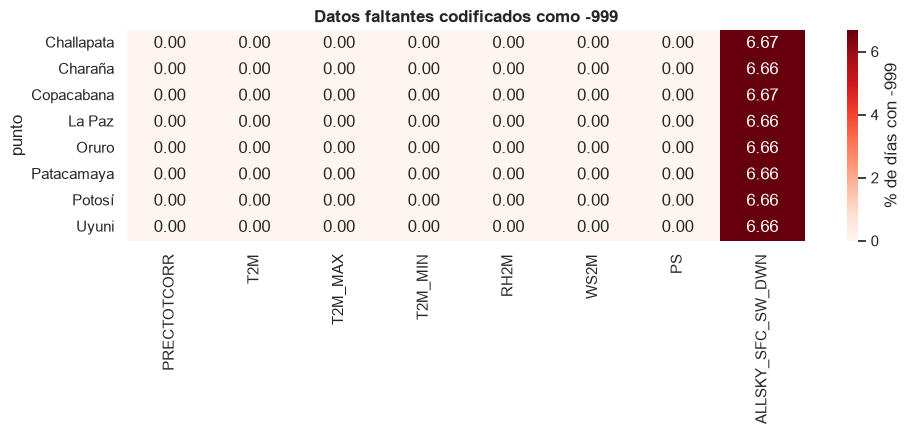

,días esperados,días presentes,huecos,fechas duplicadas
punto,,,,
Challapata,16436,16436,0,0
Charaña,16436,16436,0,0
Copacabana,16436,16436,0,0
La Paz,16436,16436,0,0
Oruro,16436,16436,0,0
Patacamaya,16436,16436,0,0
Potosí,16436,16436,0,0
Uyuni,16436,16436,0,0


In [5]:
# Porcentaje de -999 por punto y variable
pct999 = (raw[cols_p] == -999).groupby(raw["punto"]).mean() * 100
plt.figure(figsize=(10, 4.5))
sns.heatmap(pct999, annot=True, fmt=".2f", cmap="Reds", cbar_kws={"label": "% de días con -999"})
plt.title("Datos faltantes codificados como -999"); plt.tight_layout(); guardar("02_faltantes_999"); plt.show()

# Huecos de fechas y duplicados
chk = []
for p, g in raw.groupby("punto"):
    esperados = (g.index.max() - g.index.min()).days + 1
    chk.append({"punto": p, "días esperados": esperados, "días presentes": len(g),
                "huecos": esperados - len(g), "fechas duplicadas": int(g.index.duplicated().sum())})
display(pd.DataFrame(chk).set_index("punto"))

### 2.3 ¿Hay puntos duplicados? (control de calidad de la grilla)
NASA POWER usa una **grilla de ~0,5° × 0,625°** (≈ 55 × 60 km). Dos puntos que caigan en la misma celda tendrían series *idénticas*, lo que inflaría artificialmente el conjunto de datos. Se comprueba con la correlación diaria de lluvia entre puntos.

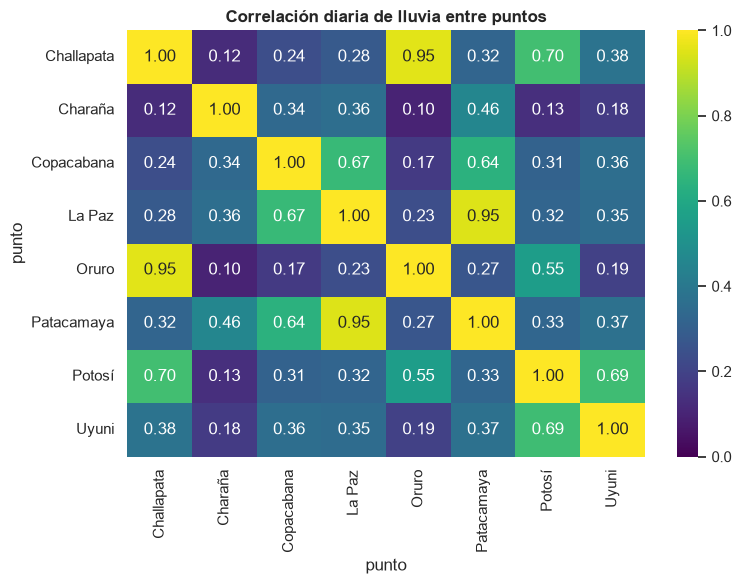

Correlación máxima entre puntos distintos: 0.9538
⚠️ Pares prácticamente idénticos: ninguno ✔


In [6]:
ll = raw.reset_index().pivot_table(index="fecha", columns="punto", values="PRECTOTCORR").replace(-999, np.nan)
corr_pts = ll.corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr_pts, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Correlación diaria de lluvia entre puntos"); plt.tight_layout(); guardar("02_corr_entre_puntos"); plt.show()
off = corr_pts.where(~np.eye(len(corr_pts), dtype=bool)).stack()
print("Correlación máxima entre puntos distintos:", round(off.max(), 4))
dup = off[off > 0.999]
print("⚠️ Pares prácticamente idénticos:", list(dup.index) if len(dup) else "ninguno ✔")

## 3. Limpieza y agregación mensual
Reglas aplicadas (`src/datos.py`):
1. `-999` → `NaN`.
2. Valores **físicamente imposibles** → `NaN` (lluvia < 0, humedad fuera de 0–100, `tmin > tmax`, etc.). La radiación POWER se mide en **MJ/m²/día**: se aceptan valores entre 0 y 50; el límite anterior de 15 descartaba valores normales.
3. **Diario → mensual**: lluvia = media diaria × días del mes (suma reescalada si faltan pocos días), `tmax` = máximo, `tmin` = mínimo, resto = media.
4. Un mes con **menos de 90 %** de cobertura queda `NaN` (no se inventan datos).
5. Se completa una malla mensual continua por punto para que los rezagos no salten meses.

In [7]:
diario, reporte = datos.limpiar_diario(raw)
print("Reporte de limpieza:")
for k, v in reporte.items():
    print(f"  {k}: {v}")
fraccion_rad_descartada = reporte["imposibles_a_NaN"]["rad"] / len(raw)
assert fraccion_rad_descartada < 0.05, "Demasiada radiación descartada: comprobar las unidades MJ/m²/día de NASA POWER"
mensual = datos.a_mensual(diario)
mensual["mes"] = mensual["fecha"].dt.month; mensual["anio"] = mensual["fecha"].dt.year
print("\nTabla mensual:", mensual.shape, "|", mensual["fecha"].min().date(), "→", mensual["fecha"].max().date())
print("\n% de NaN por variable tras la limpieza:")
display((mensual[datos.VARS].isna().mean() * 100).round(2).to_frame("% NaN").T)

Reporte de limpieza:
  filas: 131488
  valores_-999: 8762
  imposibles_a_NaN: {'lluvia': 1, 't2m': 0, 'tmax': 0, 'tmin': 0, 'rh2m': 0, 'ws2m': 0, 'ps': 0, 'rad': 0, 'tmin>tmax': 0}
  duplicados_fecha_punto: 0



Tabla mensual: (4320, 14) | 1981-01-01 → 2025-12-01

% de NaN por variable tras la limpieza:


,lluvia,t2m,tmax,tmin,rh2m,ws2m,ps,rad
% NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.67


## 4. Análisis exploratorio (EDA)
### 4.1 Estadísticos descriptivos mensuales

In [8]:
V = datos.VARS
desc = mensual[V].describe().T
desc["asimetría"] = mensual[V].skew(); desc["curtosis"] = mensual[V].kurt()
desc["% ceros"] = (mensual[V] == 0).mean() * 100
display(desc)
print("→ La lluvia mensual es muy asimétrica y con muchos ceros (estación seca). Esto condiciona el SPI y el tratamiento de outliers.")

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis,% ceros
lluvia,4320.0,37.756,42.888,0.000,5.500,21.370,57.153,546.610,1.875,6.828,1.065
t2m,4320.0,7.685,2.568,0.004,5.899,8.167,9.579,14.305,-0.499,-0.409,0.000
tmax,4320.0,19.034,2.737,11.540,16.977,18.990,21.000,27.120,0.053,-0.499,0.000
tmin,4320.0,-2.536,3.437,-16.510,-5.600,-3.060,0.530,6.180,0.249,-1.096,0.093
rh2m,4320.0,58.292,13.792,19.280,48.211,60.460,69.208,85.970,-0.430,-0.664,0.000
ws2m,4320.0,2.576,0.436,1.587,2.280,2.539,2.804,4.615,0.750,0.979,0.000
ps,4320.0,63.589,1.256,60.873,63.009,63.721,64.273,65.886,-0.451,0.046,0.000
rad,4032.0,22.832,2.917,15.253,20.579,22.561,24.799,32.325,0.390,-0.281,0.000


→ La lluvia mensual es muy asimétrica y con muchos ceros (estación seca). Esto condiciona el SPI y el tratamiento de outliers.


### 4.2 Series temporales de lluvia mensual por punto

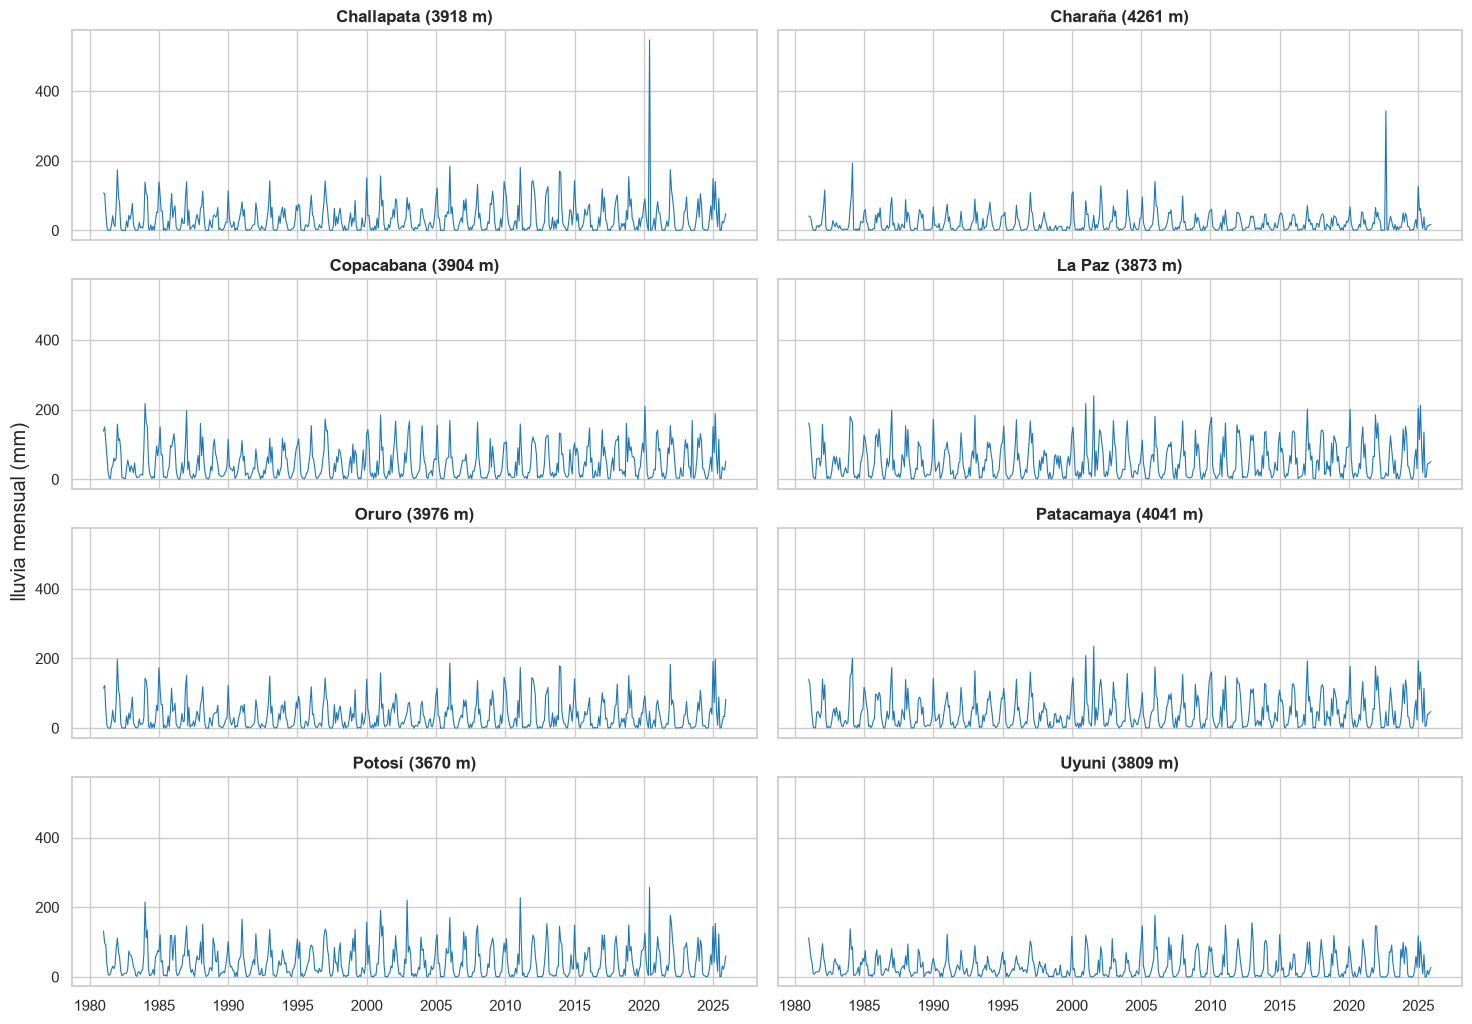

In [9]:
n = len(C.PUNTOS); filas = int(np.ceil(n / 2))
fig, axes = plt.subplots(filas, 2, figsize=(15, 2.6 * filas), sharex=True, sharey=True)
for ax, (p, g) in zip(axes.ravel(), mensual.groupby("punto")):
    ax.plot(g["fecha"], g["lluvia"], lw=0.8, color="#1f77b4"); ax.set_title(f"{p} ({g['altitud'].iloc[0]:.0f} m)")
fig.supylabel("lluvia mensual (mm)"); plt.tight_layout(); guardar("04_series_lluvia"); plt.show()

### 4.3 Estacionalidad: la temporada de lluvias

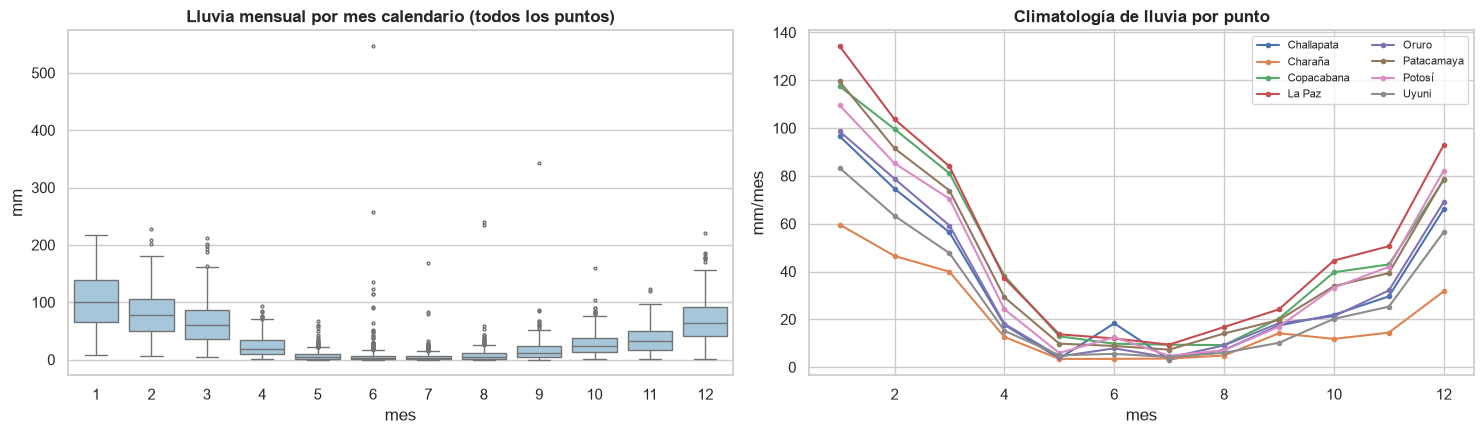

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=mensual, x="mes", y="lluvia", ax=ax[0], color="#9ecae1", fliersize=2)
ax[0].set_title("Lluvia mensual por mes calendario (todos los puntos)"); ax[0].set_ylabel("mm")
clim_ll = mensual.pivot_table(index="mes", columns="punto", values="lluvia", aggfunc="mean")
clim_ll.plot(ax=ax[1], marker="o", ms=3); ax[1].set_title("Climatología de lluvia por punto"); ax[1].set_ylabel("mm/mes")
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); guardar("04_estacionalidad"); plt.show()

### 4.4 Distribuciones (asimetría y efecto del logaritmo)

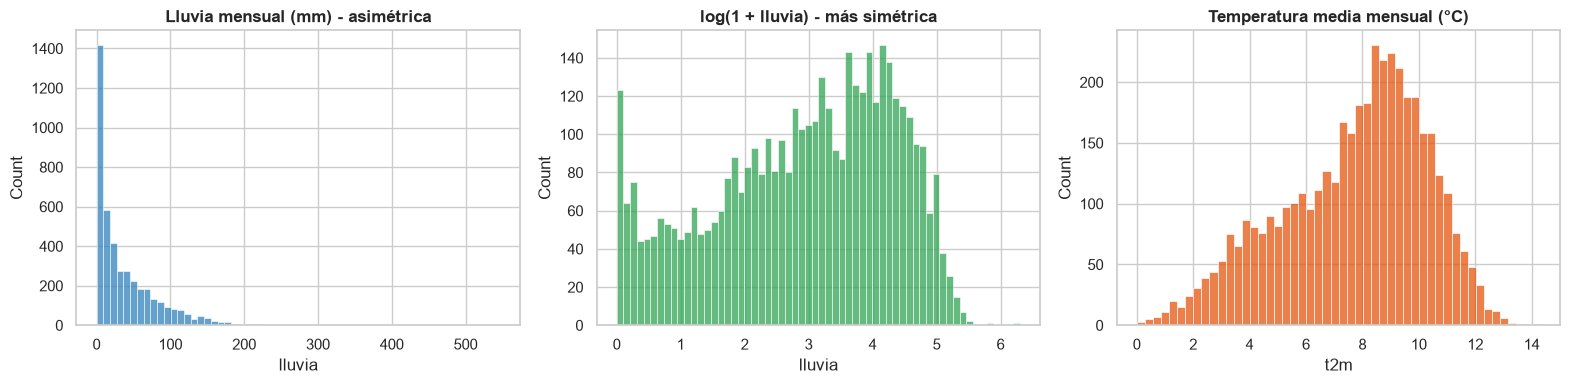

Asimetría lluvia: 1.87 → tras log1p: -0.41


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(mensual["lluvia"].dropna(), bins=60, ax=ax[0], color="#3182bd"); ax[0].set_title("Lluvia mensual (mm) - asimétrica")
sns.histplot(np.log1p(mensual["lluvia"].dropna()), bins=60, ax=ax[1], color="#31a354"); ax[1].set_title("log(1 + lluvia) - más simétrica")
sns.histplot(mensual["t2m"].dropna(), bins=50, ax=ax[2], color="#e6550d"); ax[2].set_title("Temperatura media mensual (°C)")
plt.tight_layout(); guardar("04_distribuciones"); plt.show()
print("Asimetría lluvia:", round(mensual["lluvia"].skew(), 2), "→ tras log1p:", round(np.log1p(mensual["lluvia"]).skew(), 2))

### 4.5 Correlaciones entre variables y entre puntos

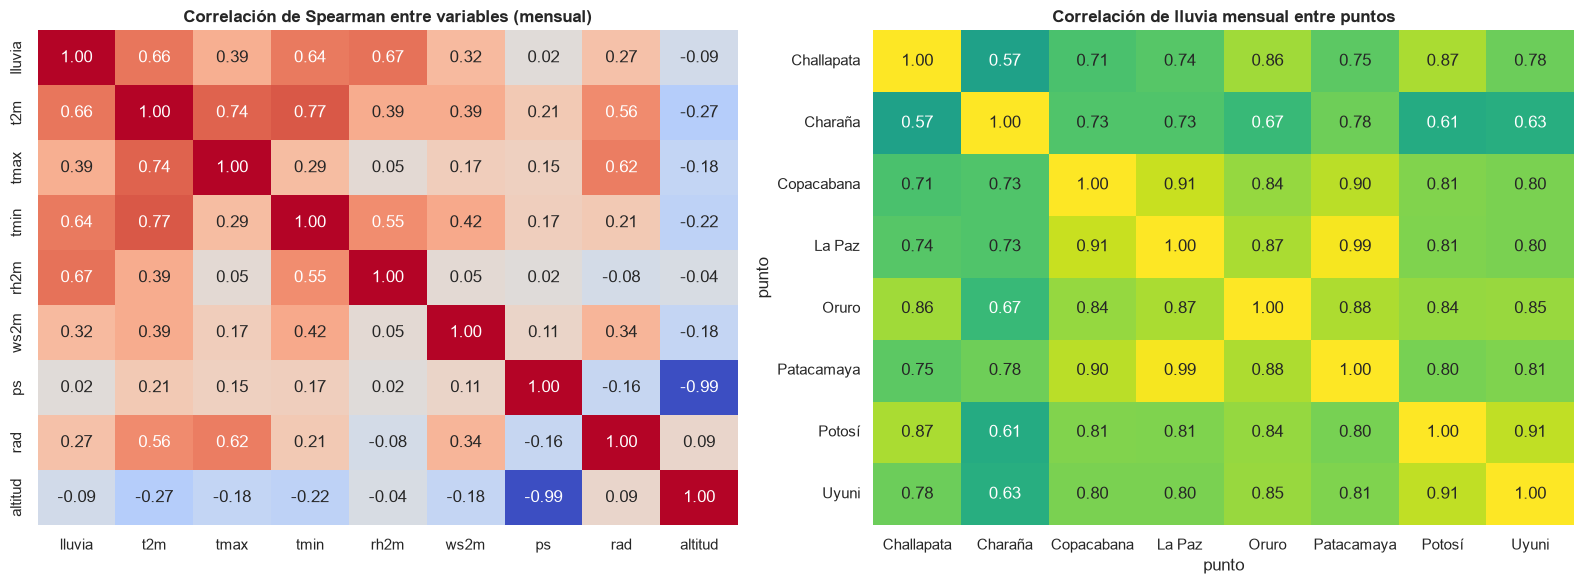

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(mensual[V + ["altitud"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Correlación de Spearman entre variables (mensual)")
sns.heatmap(mensual.pivot_table(index="fecha", columns="punto", values="lluvia").corr(), annot=True, fmt=".2f", cmap="viridis", ax=ax[1], vmin=0, vmax=1, cbar=False)
ax[1].set_title("Correlación de lluvia mensual entre puntos")
plt.tight_layout(); guardar("04_correlaciones"); plt.show()

### 4.6 Altitud, temperatura y lluvia anual · tendencia

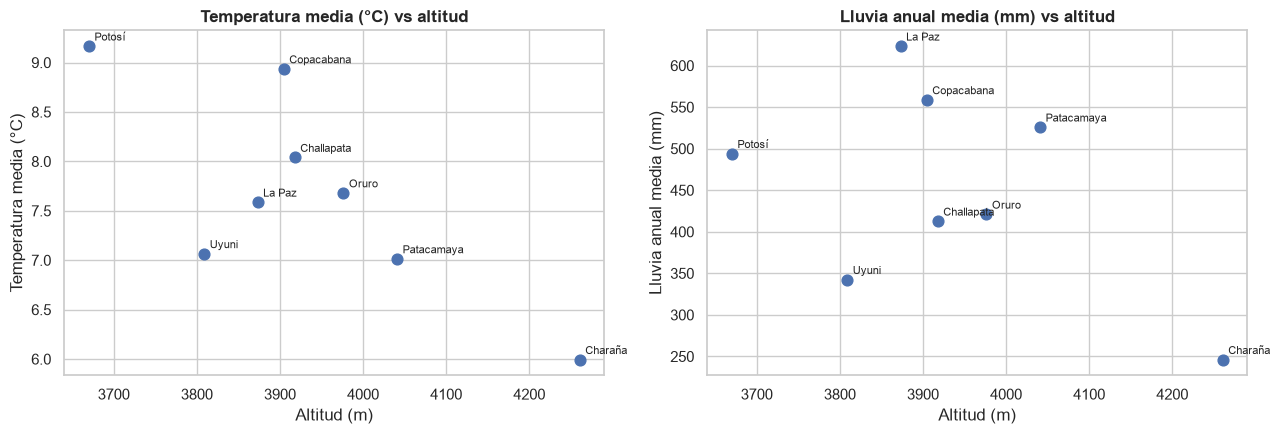

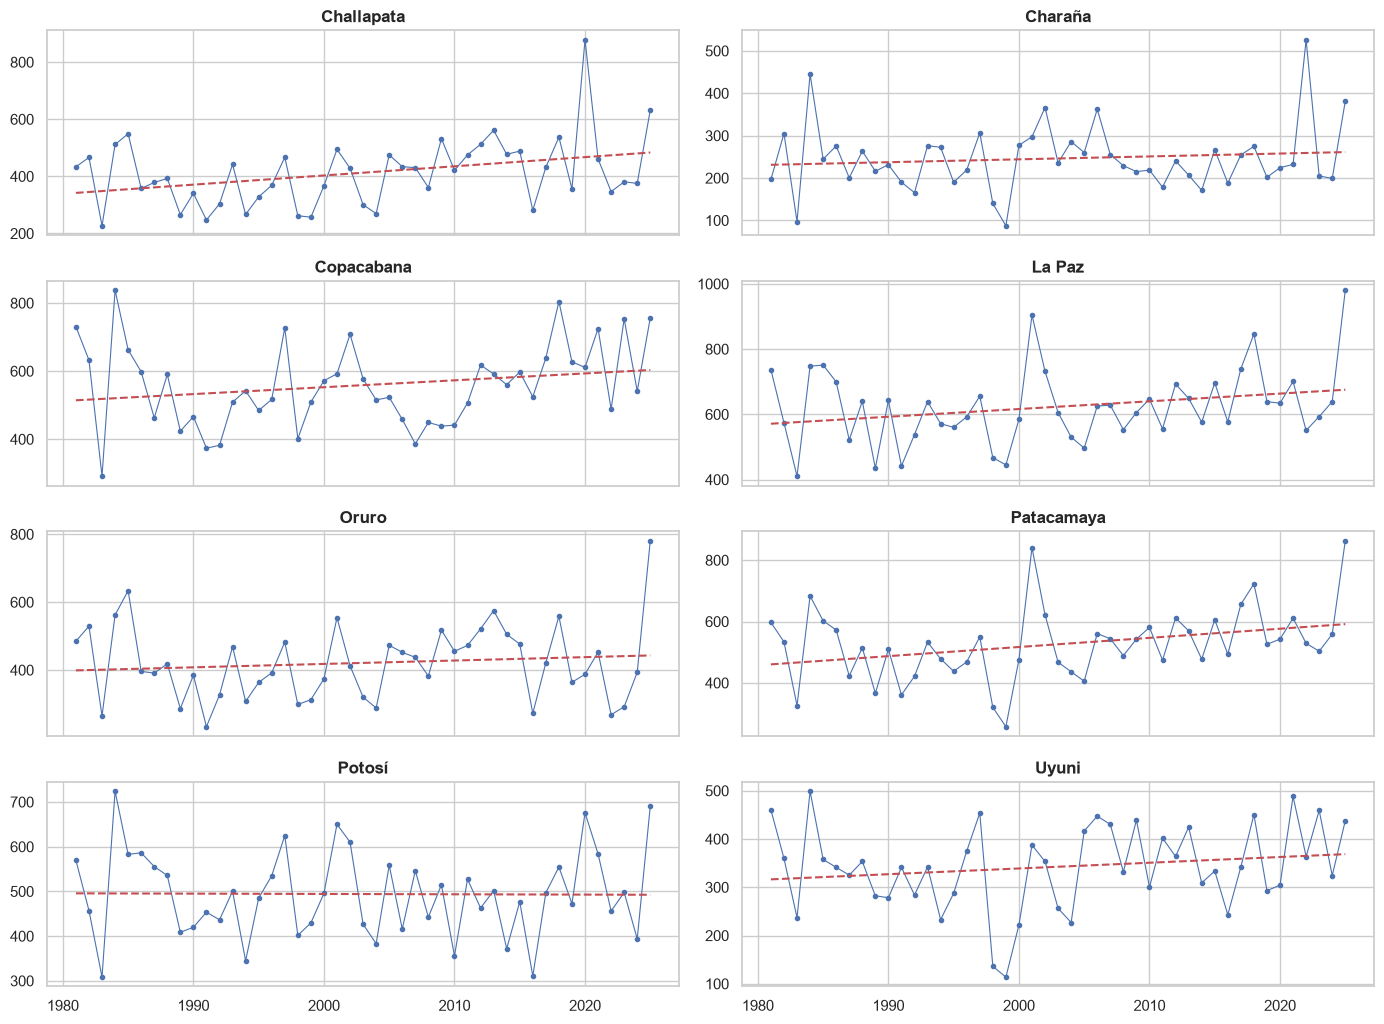

,pendiente mm/año,p-valor
punto,,
Challapata,3.211,0.018
Charaña,0.681,0.465
Copacabana,2.023,0.154
La Paz,2.366,0.076
Oruro,1.000,0.441
Patacamaya,2.980,0.028
Potosí,-0.073,0.949
Uyuni,1.188,0.243


Un p-valor < 0.05 sugiere tendencia, pero con series cortas y satelitales hay que hablar de 'tendencia observada', no de causalidad.


In [13]:
res_p = mensual.groupby("punto").agg(altitud=("altitud", "first"), t2m=("t2m", "mean"), tmin=("tmin", "min"))
anual = mensual.groupby(["punto", "anio"]).agg(lluvia=("lluvia", "sum"), n=("lluvia", "count")).reset_index()
anual = anual[anual["n"] == 12]
res_p["lluvia_anual"] = anual.groupby("punto")["lluvia"].mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, t in zip(ax, ["t2m", "lluvia_anual"], ["Temperatura media (°C)", "Lluvia anual media (mm)"]):
    a.scatter(res_p["altitud"], res_p[col], s=60)
    for p, r in res_p.iterrows(): a.annotate(p, (r["altitud"], r[col]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    a.set_xlabel("Altitud (m)"); a.set_ylabel(t); a.set_title(f"{t} vs altitud")
plt.tight_layout(); guardar("04_altitud"); plt.show()

# Tendencia lineal de la lluvia anual (con cautela: 45 años de datos satelitales)
tend = []
fig, axes = plt.subplots(filas, 2, figsize=(14, 2.6 * filas), sharex=True)
for ax_, (p, g) in zip(axes.ravel(), anual.groupby("punto")):
    lr = stats.linregress(g["anio"], g["lluvia"]); tend.append({"punto": p, "pendiente mm/año": lr.slope, "p-valor": lr.pvalue})
    ax_.plot(g["anio"], g["lluvia"], marker="o", ms=3, lw=0.8); ax_.plot(g["anio"], lr.intercept + lr.slope * g["anio"], "r--"); ax_.set_title(p)
plt.tight_layout(); guardar("04_tendencia_anual"); plt.show()
display(pd.DataFrame(tend).set_index("punto"))
print("Un p-valor < 0.05 sugiere tendencia, pero con series cortas y satelitales hay que hablar de 'tendencia observada', no de causalidad.")

## 5. Outliers: detección y tratamiento
Se aplican tres métodos y luego se **decide caso por caso** qué es un *error* (se corrige) y qué es un *extremo real* (se conserva).

> **Idea clave:** en lluvia, un outlier estadístico suele ser un **evento extremo genuino** (justo lo que interesa). Un IQR global marcaría casi toda la temporada lluviosa; hay que calcularlo **por punto y mes calendario**.
### 5.1 Regla del rango intercuartílico (IQR)
`límite inferior = Q1 − 1,5·IQR` · `límite superior = Q3 + 1,5·IQR`

In [14]:
VARS_OUT = ["lluvia", "t2m", "tmax", "tmin", "rh2m", "ws2m", "ps", "rad"]
def flag_iqr_global(df, col, k=1.5):
    g = df.groupby("punto")[col]
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    return (df[col] < q1 - k * (q3 - q1)) | (df[col] > q3 + k * (q3 - q1))

def flag_iqr_mes(df, col, k=1.5, guarda=True):
    # guarda=False: IQR puro por mes; guarda=True: si IQR=0 usa el percentil 99 (src/features.limites_iqr)
    if guarda:
        lim = F.limites_iqr(df, col, np.ones(len(df), bool), k)
        j = df[["punto", "mes"]].join(lim[["lo", "hi"]], on=["punto", "mes"])
        return (df[col] < j["lo"]) | (df[col] > j["hi"])
    g = df.groupby(["punto", "mes"])[col]
    q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
    return (df[col] < q1 - k * (q3 - q1)) | (df[col] > q3 + k * (q3 - q1))

tab = pd.DataFrame({
    "IQR global (por punto)": {v: flag_iqr_global(mensual, v).mean() * 100 for v in VARS_OUT},
    "IQR por mes (puro)": {v: flag_iqr_mes(mensual, v, guarda=False).mean() * 100 for v in VARS_OUT},
    "IQR por mes + guarda p99": {v: flag_iqr_mes(mensual, v, guarda=True).mean() * 100 for v in VARS_OUT},
})
print("% de observaciones marcadas como outlier:")
display(tab.round(2))
print("→ En lluvia, el IQR puro por mes marca de más en meses secos (IQR=0 ⇒ cualquier llovizna es 'outlier'); la guarda p99 lo corrige.")

% de observaciones marcadas como outlier:


,IQR global (por punto),IQR por mes (puro),IQR por mes + guarda p99
lluvia,3.52,4.38,4.38
t2m,0.07,2.85,2.85
tmax,0.00,2.34,2.34
tmin,0.25,2.15,2.15
rh2m,0.02,1.76,1.76
ws2m,0.42,1.94,1.94
ps,0.09,2.27,2.27
rad,0.14,2.34,2.34


→ En lluvia, el IQR puro por mes marca de más en meses secos (IQR=0 ⇒ cualquier llovizna es 'outlier'); la guarda p99 lo corrige.


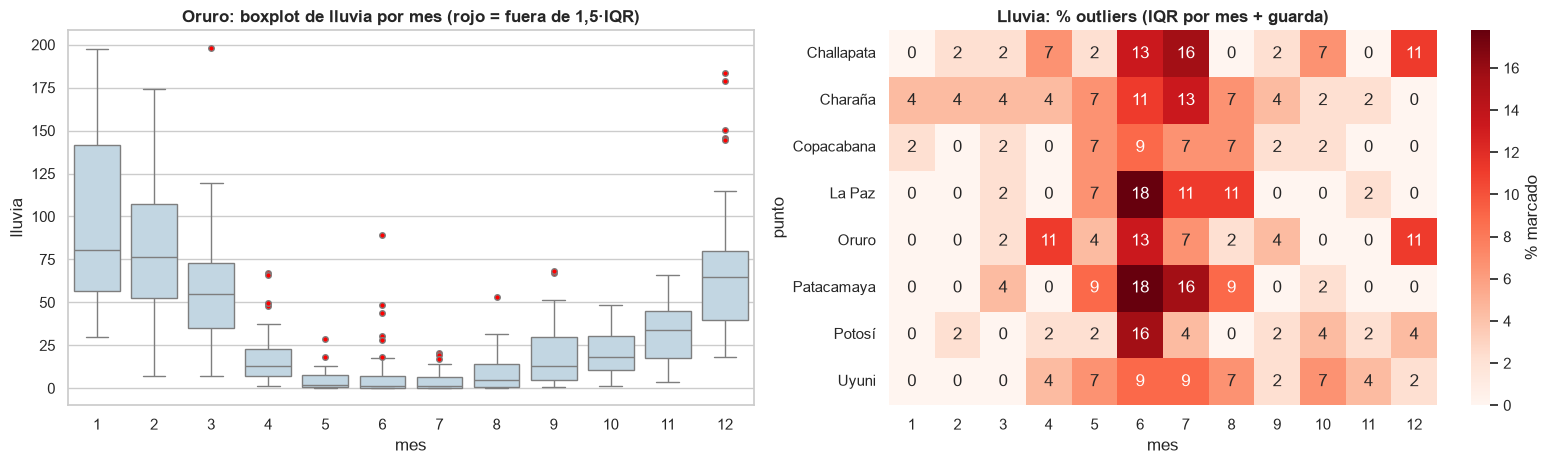

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
punto_demo = "Oruro" if "Oruro" in C.PUNTOS else list(C.PUNTOS)[0]
sns.boxplot(data=mensual[mensual["punto"] == punto_demo], x="mes", y="lluvia", ax=ax[0], color="#bdd7e7", fliersize=4, flierprops={"markerfacecolor": "red"})
ax[0].set_title(f"{punto_demo}: boxplot de lluvia por mes (rojo = fuera de 1,5·IQR)")
hm = mensual.assign(f=flag_iqr_mes(mensual, "lluvia")).pivot_table(index="punto", columns="mes", values="f", aggfunc="mean") * 100
sns.heatmap(hm, annot=True, fmt=".0f", cmap="Reds", ax=ax[1], cbar_kws={"label": "% marcado"}); ax[1].set_title("Lluvia: % outliers (IQR por mes + guarda)")
plt.tight_layout(); guardar("05_outliers_iqr"); plt.show()

### 5.2 Z-score modificado (mediana y MAD)
Robusto a la asimetría: `z = 0,6745·(x − mediana)/MAD`, se marca |z| > 3,5 (Iglewicz & Hoaglin). Si MAD = 0 (meses secos) no se evalúa.

In [16]:
def flag_mad(df, col, umbral=3.5):
    g = df.groupby(["punto", "mes"])[col]
    med = g.transform("median"); mad = g.transform(lambda s: (s - s.median()).abs().median())
    z = 0.6745 * (df[col] - med) / mad.replace(0, np.nan)
    return z.abs() > umbral
tab_mad = pd.Series({v: flag_mad(mensual, v).mean() * 100 for v in VARS_OUT}, name="% marcado (MAD)")
display(tab_mad.round(2).to_frame().T)

,lluvia,t2m,tmax,tmin,rh2m,ws2m,ps,rad
% marcado (MAD),5.07,0.69,0.62,0.72,0.69,0.32,0.53,0.69


### 5.3 Isolation Forest (multivariado)
Detecta **combinaciones** raras de variables aunque cada una, por separado, sea normal. Se aplica sobre las anomalías estandarizadas por punto y mes.

Meses marcados por Isolation Forest: 81 (1.9%)


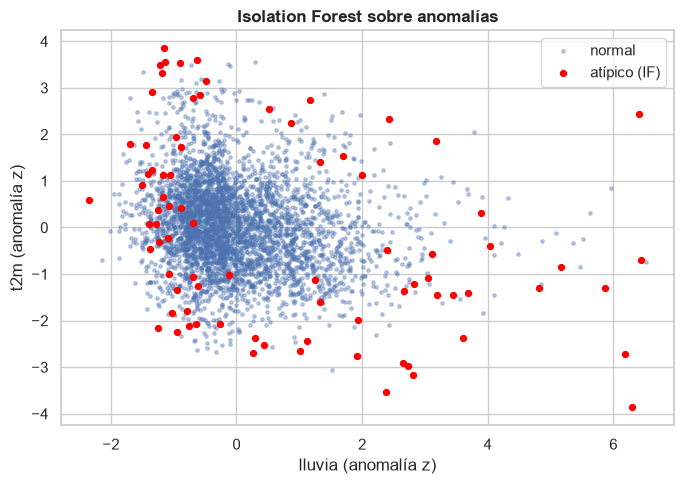

In [17]:
Z = mensual[["punto", "mes"] + V].copy()
for v in V:
    g = Z.groupby(["punto", "mes"])[v]
    Z[v] = (Z[v] - g.transform("mean")) / g.transform("std").replace(0, np.nan)
Z = Z.dropna(subset=V)
iso = IsolationForest(contamination=0.02, n_estimators=300, random_state=C.SEMILLA).fit(Z[V])
Z["if_flag"] = iso.predict(Z[V]) == -1
Z["if_score"] = -iso.score_samples(Z[V])
mensual["flag_if"] = Z["if_flag"].reindex(mensual.index).fillna(False).astype(bool)
print("Meses marcados por Isolation Forest:", int(mensual["flag_if"].sum()), f"({mensual['flag_if'].mean()*100:.1f}%)")
plt.figure(figsize=(7, 5))
plt.scatter(Z.loc[~Z["if_flag"], "lluvia"], Z.loc[~Z["if_flag"], "t2m"], s=6, alpha=.35, label="normal")
plt.scatter(Z.loc[Z["if_flag"], "lluvia"], Z.loc[Z["if_flag"], "t2m"], s=18, c="red", label="atípico (IF)")
plt.xlabel("lluvia (anomalía z)"); plt.ylabel("t2m (anomalía z)"); plt.legend(); plt.title("Isolation Forest sobre anomalías")
plt.tight_layout(); guardar("05_isolation_forest"); plt.show()

### 5.4 Clasificación: ¿error o extremo real?
Se combinan los tres métodos por **votos** y se revisan las reglas físicas. Criterio:

| Situación | Decisión |
|---|---|
| Físicamente imposible (ya convertido a `NaN` en la limpieza) | **Error** → imputar/excluir |
| Marcado por IQR **y** MAD **y** Isolation Forest, físicamente plausible | **Extremo real candidato** → **se conserva** |
| Marcado por un solo método | Variabilidad normal → se conserva |

In [18]:
mensual["f_iqr"] = flag_iqr_mes(mensual, "lluvia"); mensual["f_mad"] = flag_mad(mensual, "lluvia")
mensual["votos"] = mensual[["f_iqr", "f_mad", "flag_if"]].sum(axis=1)
display(mensual["votos"].value_counts().sort_index().rename("meses").to_frame())
cand = mensual[mensual["votos"] == 3].sort_values("lluvia", ascending=False)[["punto", "fecha", "lluvia", "t2m", "rh2m"]].head(12)
print("Extremos reales candidatos (3 votos) - mayores lluvias mensuales:"); display(cand)
n100 = int((diario["lluvia"] > 100).sum())
print(f"Días con lluvia > 100 mm en el diario: {n100}  → revisar contra CHIRPS si se quiere confirmar eventos puntuales.")
print("Errores físicos ya anulados en la limpieza:", reporte["imposibles_a_NaN"])

,meses
votos,
0,4005
1,160
2,136
3,19


Extremos reales candidatos (3 votos) - mayores lluvias mensuales:


,punto,fecha,lluvia,t2m,rh2m
473,Challapata,2020-06-01,546.61,3.226,54.780
3713,Potosí,2020-06-01,257.01,4.793,52.888
1867,La Paz,2001-08-01,239.55,4.099,75.681
2947,Patacamaya,2001-08-01,235.12,1.536,77.315
2690,Oruro,2025-03-01,198.36,8.873,79.579
578,Charaña,1984-03-01,193.10,6.808,74.951
2651,Oruro,2021-12-01,183.32,9.415,70.816
1590,Copacabana,2023-07-01,169.13,8.982,55.604
3773,Potosí,2025-06-01,123.57,4.732,59.649
3298,Potosí,1985-11-01,119.26,9.565,66.471


Días con lluvia > 100 mm en el diario: 5  → revisar contra CHIRPS si se quiere confirmar eventos puntuales.
Errores físicos ya anulados en la limpieza: {'lluvia': 1, 't2m': 0, 'tmax': 0, 'tmin': 0, 'rh2m': 0, 'ws2m': 0, 'ps': 0, 'rad': 0, 'tmin>tmax': 0}


**Decisión:** los extremos reales **no se eliminan**. En la sección 10 se compara experimentalmente su tratamiento (dejarlos, `log1p`, winsorización) para ver cómo afecta al desempeño.

## 6. SPI y variable objetivo
**SPI** (Índice Estandarizado de Precipitación, OMM): se ajusta una distribución gamma mixta a la lluvia acumulada (1, 3 y 6 meses) de cada punto y mes calendario **en el periodo de referencia 1981–2010**, y se transforma a una normal estándar.

`sequía = 1` si **SPI-3 del mes t+h ≤ −1** (sequía moderada o peor). Es una etiqueta objetiva y reproducible; **no requiere un pronóstico oficial**.

In [19]:
params = {k: S.ajustar_parametros(mensual, k) for k in C.ESCALAS_SPI}
ms = S.agregar_spi(mensual, params)
print("Parámetros gamma SPI-3 (ejemplo, primer punto):")
display(params[3].loc[list(C.PUNTOS)[0]].round(3).T)

ref = ms[(ms["anio"] >= C.REF_INI) & (ms["anio"] <= C.REF_FIN)]
chk = ref.groupby("punto")[["spi1", "spi3", "spi6"]].agg(["mean", "std"]).round(2)
print("\nVerificación en el periodo de referencia (esperado: media ≈ 0, desviación ≈ 1):"); display(chk)

Parámetros gamma SPI-3 (ejemplo, primer punto):


mes,1,2,3,4,5,6,7,8,9,10,11,12
q,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
a,21.810,15.733,15.336,11.140,10.312,5.481,2.523,1.414,2.139,4.015,9.069,16.988
esc,12.505,19.791,20.254,18.781,12.100,9.841,11.197,27.014,25.606,22.068,13.355,10.600



Verificación en el periodo de referencia (esperado: media ≈ 0, desviación ≈ 1):


spi1        spi3        spi6      
            mean   std  mean   std  mean   std
punto                                         
Challapata  0.01  0.98  0.00  1.00  0.00  1.00
Charaña    -0.01  0.99 -0.00  0.99  0.00  0.99
Copacabana -0.00  1.00 -0.00  1.00  0.00  1.00
La Paz     -0.01  0.99 -0.01  0.97 -0.01  0.98
Oruro      -0.00  0.99  0.00  1.00  0.00  1.00
Patacamaya -0.01  0.99 -0.01  0.96 -0.01  0.96
Potosí     -0.00  1.00 -0.00  1.00 -0.00  1.00
Uyuni       0.01  1.00  0.00  1.00  0.00  0.99

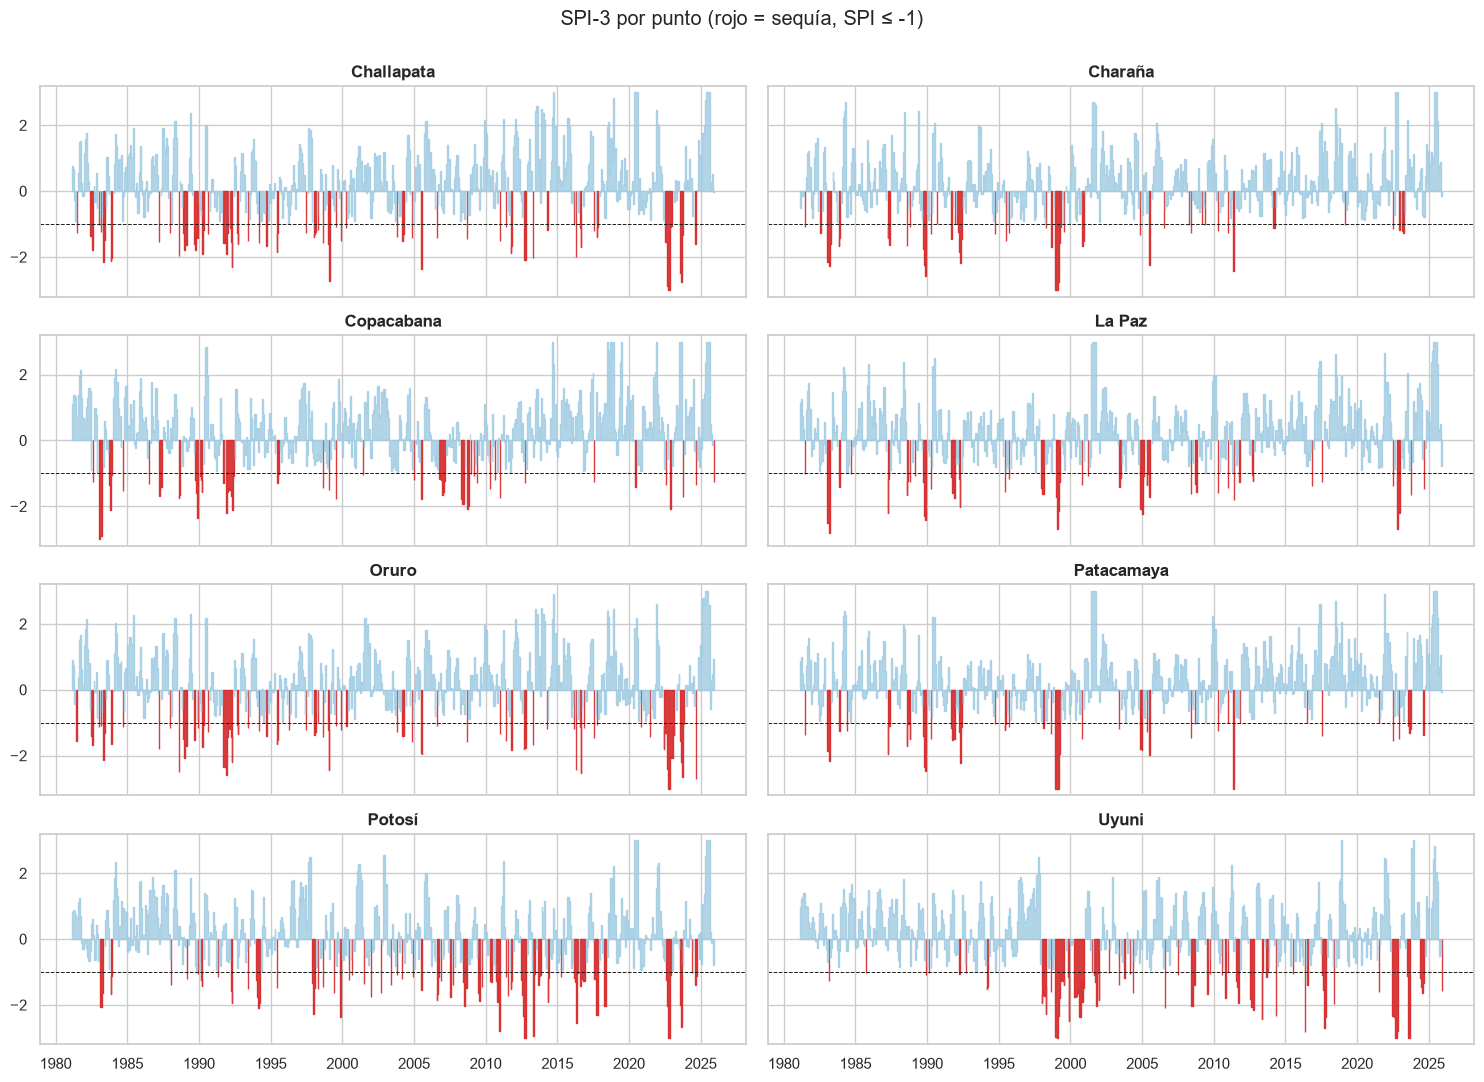

In [20]:
fig, axes = plt.subplots(filas, 2, figsize=(15, 2.7 * filas), sharex=True, sharey=True)
for ax, (p, g) in zip(axes.ravel(), ms.groupby("punto")):
    ax.fill_between(g["fecha"], g["spi3"], 0, where=g["spi3"] <= -1, color="#d62728", alpha=.9, step="mid")
    ax.fill_between(g["fecha"], g["spi3"], 0, where=g["spi3"] > -1, color="#9ecae1", alpha=.8, step="mid")
    ax.axhline(-1, color="k", ls="--", lw=.7); ax.set_title(p); ax.set_ylim(-3.2, 3.2)
fig.suptitle("SPI-3 por punto (rojo = sequía, SPI ≤ -1)", y=1.0); plt.tight_layout(); guardar("06_spi3_series"); plt.show()

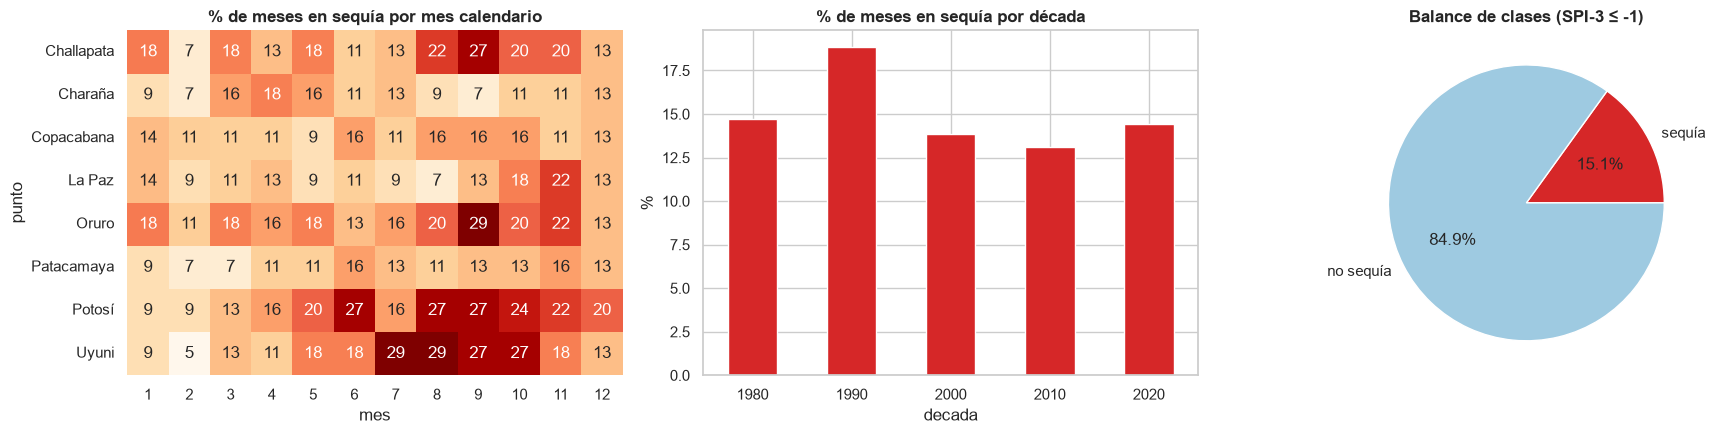

Nota: la década de 1980 incluye el periodo de referencia, y la de 2020 es parcial.
Si la frecuencia es alta en meses secos (mayo-sep), suele ser un artefacto de acumulados ≈ 0 (ver sección 17).


In [21]:
ms["seq"] = np.where(ms["spi3"].isna(), np.nan, (ms["spi3"] <= C.UMBRAL_SEQUIA).astype(float))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
hm = ms.pivot_table(index="punto", columns="mes", values="seq", aggfunc="mean") * 100
sns.heatmap(hm, annot=True, fmt=".0f", cmap="OrRd", ax=ax[0], cbar=False); ax[0].set_title("% de meses en sequía por mes calendario")
dec = ms.assign(decada=(ms["anio"] // 10) * 10).groupby("decada")["seq"].mean() * 100
dec.plot.bar(ax=ax[1], color="#d62728"); ax[1].set_title("% de meses en sequía por década"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
ax[2].pie([ms["seq"].mean(), 1 - ms["seq"].mean()], labels=["sequía", "no sequía"], autopct="%1.1f%%", colors=["#d62728", "#9ecae1"]); ax[2].set_title("Balance de clases (SPI-3 ≤ -1)")
plt.tight_layout(); guardar("06_frecuencia_sequia"); plt.show()
print("Nota: la década de 1980 incluye el periodo de referencia, y la de 2020 es parcial.")
print("Si la frecuencia es alta en meses secos (mayo-sep), suele ser un artefacto de acumulados ≈ 0 (ver sección 17).")

### 6.1 Relación con El Niño (ONI)

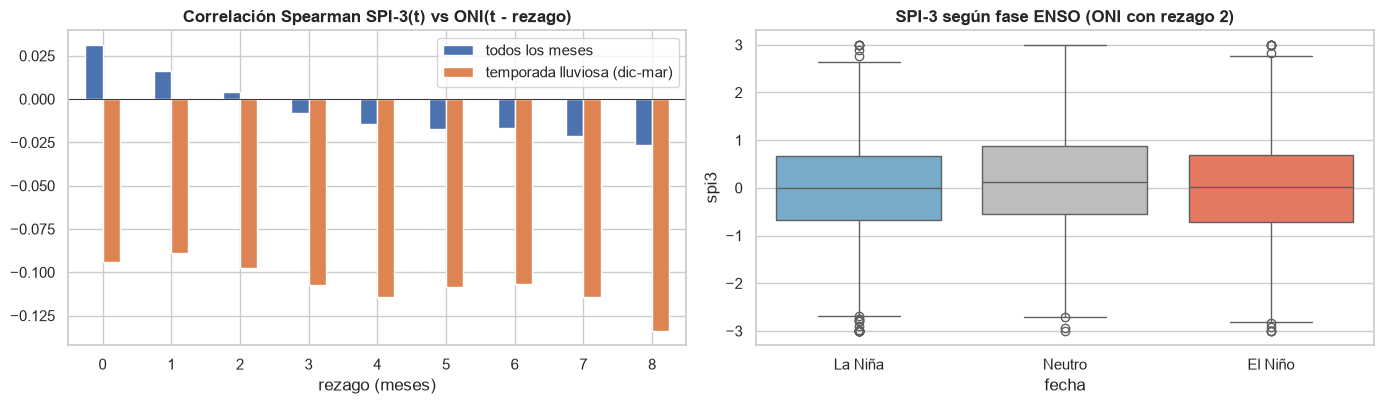

,todos los meses,temporada lluviosa (dic-mar)
rezago (meses),,
0,0.031,-0.094
1,0.016,-0.089
2,0.004,-0.097
3,-0.008,-0.107
4,-0.014,-0.114
5,-0.017,-0.108
6,-0.017,-0.107
7,-0.021,-0.114
8,-0.027,-0.134


In [22]:
oni_map = oni.set_index("fecha")["oni"]
filas_l = []
for lag in range(0, 9):
    x = ms["fecha"].sub(pd.DateOffset(months=lag)).map(oni_map)
    ok = x.notna() & ms["spi3"].notna()
    llu = ms["mes"].isin([12, 1, 2, 3])
    filas_l.append({"rezago (meses)": lag, "todos los meses": stats.spearmanr(x[ok], ms.loc[ok, "spi3"])[0],
                    "temporada lluviosa (dic-mar)": stats.spearmanr(x[ok & llu], ms.loc[ok & llu, "spi3"])[0]})
cc = pd.DataFrame(filas_l).set_index("rezago (meses)")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
cc.plot.bar(ax=ax[0]); ax[0].axhline(0, color="k", lw=.6); ax[0].set_title("Correlación Spearman SPI-3(t) vs ONI(t - rezago)"); ax[0].tick_params(axis="x", rotation=0)
fase = pd.cut(ms["fecha"].sub(pd.DateOffset(months=2)).map(oni_map), [-9, -0.5, 0.5, 9], labels=["La Niña", "Neutro", "El Niño"])
sns.boxplot(x=fase, y=ms["spi3"], ax=ax[1], palette=["#6baed6", "#bdbdbd", "#fb6a4a"]); ax[1].set_title("SPI-3 según fase ENSO (ONI con rezago 2)")
plt.tight_layout(); guardar("06_oni_vs_spi"); plt.show()
display(cc.round(3))

## 7. Ingeniería de variables y particiones temporales
**Predictores (en el mes *t*):** lluvia y rezagos (1, 2, 3, 6 meses), acumulados de 3 y 6 meses, SPI-1/3/6 y rezagos, temperatura/humedad/viento/presión/radiación, **anomalías** respecto a la climatología 1981–2010, estacionalidad cíclica (seno y coseno del mes), **ONI con rezago 2 y 3 meses** (el ONI se publica con retraso y sus valores recientes se revisan hasta ~2 meses después, por eso no se usa el valor “actual”) y la altitud.

**Objetivo:** `y_h{h}` = ¿SPI-3 del mes *t+h* ≤ −1?

**Particiones (por fecha, nunca al azar):** entrenamiento ≤ 2012 · validación 2013–2018 · **prueba 2019 en adelante (se usa una sola vez)**. Se recorta la fecha objetivo (*t+h*) de cada partición para que ninguna etiqueta “mire” al periodo siguiente.

In [23]:
clim = F.calcular_climatologia(mensual)
d = F.construir_features(ms, oni, clim)
FEATS = F.lista_features()
print(f"Tabla de modelado: {d.shape} | predictores: {len(FEATS)}")
print(FEATS)
print("\n% NaN en predictores (los primeros 6 meses de cada punto no tienen rezagos):")
display((d[FEATS].isna().mean() * 100).round(1).sort_values(ascending=False).head(8).to_frame("% NaN").T)

Tabla de modelado: (4320, 48) | predictores: 30
['lluvia', 'lluvia_l1', 'lluvia_l2', 'lluvia_l3', 'lluvia_l6', 'acum3', 'acum6', 'spi1', 'spi3', 'spi6', 'spi1_l1', 'spi3_l1', 'spi3_l2', 'spi3_l3', 't2m', 'tmax', 'tmin', 'rh2m', 'ws2m', 'ps', 'rad', 't2m_anom', 'tmin_anom', 'tmax_anom', 'rh2m_anom', 'mes_sin', 'mes_cos', 'oni_l2', 'oni_l3', 'altitud']

% NaN en predictores (los primeros 6 meses de cada punto no tienen rezagos):


,rad,lluvia_l6,spi6,spi3_l3,acum6,spi3_l2,spi3_l1,lluvia_l3
% NaN,6.7,1.1,0.9,0.9,0.9,0.7,0.6,0.6


filas       desde       hasta  % sequía
h partición                                         
1 train       2776  1984-01-01  2012-11-01      15.9
  val          568  2013-01-01  2018-11-01      11.3
  test         664  2019-01-01  2025-11-01      12.7
2 train       2768  1984-01-01  2012-10-01      15.9
  val          560  2013-01-01  2018-10-01      11.4
  test         656  2019-01-01  2025-10-01      12.8
3 train       2760  1984-01-01  2012-09-01      16.0
  val          552  2013-01-01  2018-09-01      11.6
  test         648  2019-01-01  2025-09-01      12.8

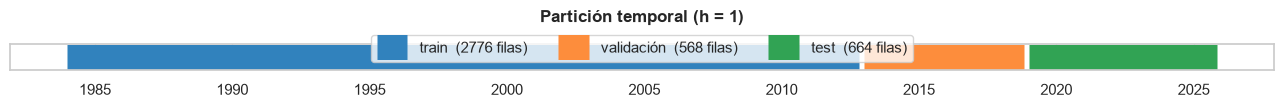

In [24]:
rows = []
for h in C.HORIZONTES:
    a, b, c = F.particionar(d, h, FEATS)
    for nombre, x in zip(["train", "val", "test"], [a, b, c]):
        rows.append({"h": h, "partición": nombre, "filas": len(x), "desde": x["fecha"].min().date(), "hasta": x["fecha"].max().date(),
                     "% sequía": x[f"y_h{h}"].mean() * 100})
display(pd.DataFrame(rows).set_index(["h", "partición"]).round(1))

H = 1; Y = f"y_h{H}"
tr, va, te = F.particionar(d, H, FEATS)
# comprobación anti-fuga
assert tr["fecha"].max() < va["fecha"].min() and va["fecha"].max() < te["fecha"].min()
fig, ax = plt.subplots(figsize=(13, 1.8))
for x, c, n in zip([tr, va, te], ["#3182bd", "#fd8d3c", "#31a354"], ["train", "validación", "test"]):
    ax.hlines(0, x["fecha"].min(), x["fecha"].max(), color=c, lw=18, label=f"{n}  ({len(x)} filas)")
ax.set_yticks([]); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, 1.6)); ax.set_title("Partición temporal (h = 1)", y=1.5)
plt.tight_layout(); guardar("07_particion_temporal"); plt.show()

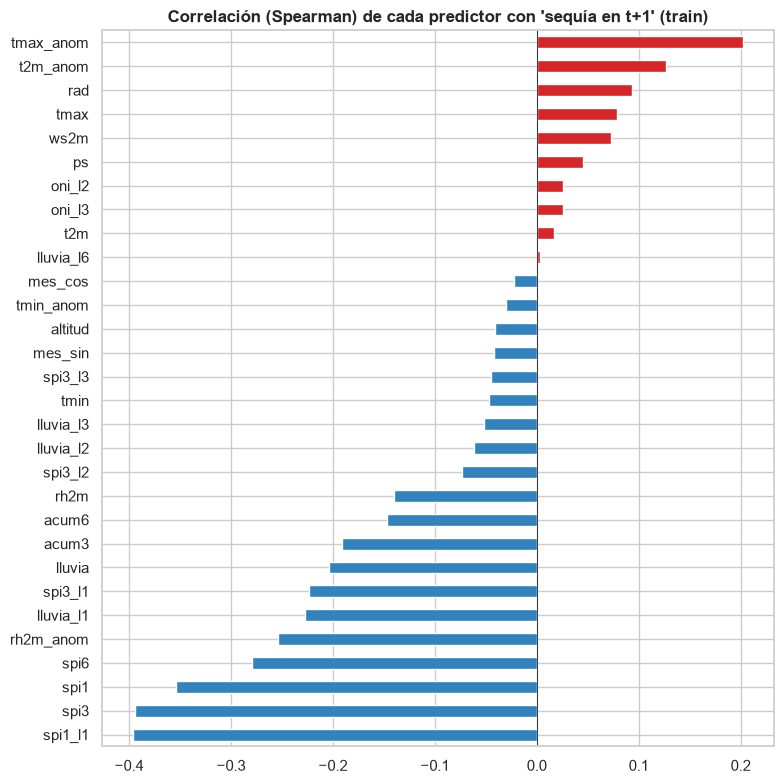

In [25]:
# Relación univariada con el objetivo (Spearman) en train
cor = tr[FEATS].apply(lambda s: stats.spearmanr(s, tr[Y])[0]).sort_values()
plt.figure(figsize=(8, 8)); cor.plot.barh(color=np.where(cor > 0, "#d62728", "#3182bd")); plt.axvline(0, color="k", lw=.6)
plt.title("Correlación (Spearman) de cada predictor con 'sequía en t+1' (train)"); plt.tight_layout(); guardar("07_correlacion_objetivo"); plt.show()

## 8. Líneas base
Un modelo solo vale si **supera a alternativas triviales**:
- **Siempre “no sequía”** (accuracy alta pero inútil).
- **Persistencia**: si hoy hay sequía, mañana también.
- **Climatología**: la frecuencia histórica de sequía de ese mes y punto.

In [26]:
base_val = M.lineas_base(tr, va, Y, Y)
display(base_val.round(3))
print(f"Prevalencia de sequía en validación: {va[Y].mean()*100:.1f}%  (un PR-AUC al azar ≈ esa prevalencia)")

,F1,Precisión,Recall,Bal.Acc,Brier,PR-AUC,ROC-AUC
Modelo,,,,,,,
Base: siempre 'no sequía',0.000,0.000,0.000,0.500,0.113,0.113,0.500
Base: persistencia,0.422,0.422,0.422,0.674,0.130,0.243,0.674
Base: climatología,0.249,0.154,0.656,0.599,0.099,0.179,0.642


Prevalencia de sequía en validación: 11.3%  (un PR-AUC al azar ≈ esa prevalencia)


## 9. Comparación de modelos (h = 1)
Se entrenan 10 modelos en *train* y se evalúan en *validación*. La CV de esta exploración es temporal, pero sus primeros pliegues usan SPI y climatología de la referencia 1981–2010, que todavía no habría terminado. La selección final de la sección 12 usa únicamente pliegues de 2011–2018. Métricas: **PR-AUC** y **F1 de sequía**.

In [27]:
spw = (1 - tr[Y].mean()) / tr[Y].mean()
catalogo = M.catalogo_modelos(scale_pos_weight=spw)
res, fit = M.comparar_modelos(catalogo, tr[FEATS], tr[Y], va[FEATS], va[Y], tr["fecha"], gap_meses=H)
res_show = res[["F1 (val)", "Precisión (val)", "Recall (val)", "PR-AUC (val)", "ROC-AUC (val)", "Brier (val)", "PR-AUC (CV)", "F1 (CV)", "umbral"]]
display(res_show.round(3))

  Regresión logística    F1 val=0.556  PR-AUC val=0.551
  KNN                    F1 val=0.410  PR-AUC val=0.445


  SVM (RBF)              F1 val=0.489  PR-AUC val=0.585


  Árbol de decisión      F1 val=0.453  PR-AUC val=0.480


  Random Forest          F1 val=0.533  PR-AUC val=0.589


  Extra Trees            F1 val=0.536  PR-AUC val=0.574


  Gradient Boosting      F1 val=0.565  PR-AUC val=0.629


  MLP                    F1 val=0.512  PR-AUC val=0.564


  XGBoost                F1 val=0.525  PR-AUC val=0.598


  LightGBM               F1 val=0.521  PR-AUC val=0.601


,F1 (val),Precisión (val),Recall (val),PR-AUC (val),ROC-AUC (val),Brier (val),PR-AUC (CV),F1 (CV),umbral
Modelo,,,,,,,,,
Gradient Boosting,0.565,0.453,0.750,0.629,0.919,0.067,0.540,0.579,0.189
LightGBM,0.521,0.371,0.875,0.601,0.913,0.076,0.504,0.561,0.035
XGBoost,0.525,0.388,0.812,0.598,0.918,0.080,0.506,0.569,0.183
Random Forest,0.533,0.384,0.875,0.589,0.925,0.066,0.482,0.573,0.197
SVM (RBF),0.489,0.342,0.859,0.585,0.907,0.073,0.481,0.538,0.084
Extra Trees,0.536,0.400,0.812,0.574,0.924,0.077,0.476,0.557,0.340
MLP,0.512,0.413,0.672,0.564,0.881,0.073,0.479,0.487,0.239
Regresión logística,0.556,0.431,0.781,0.551,0.914,0.117,0.608,0.615,0.602
Árbol de decisión,0.453,0.425,0.484,0.480,0.857,0.116,0.336,0.496,0.695


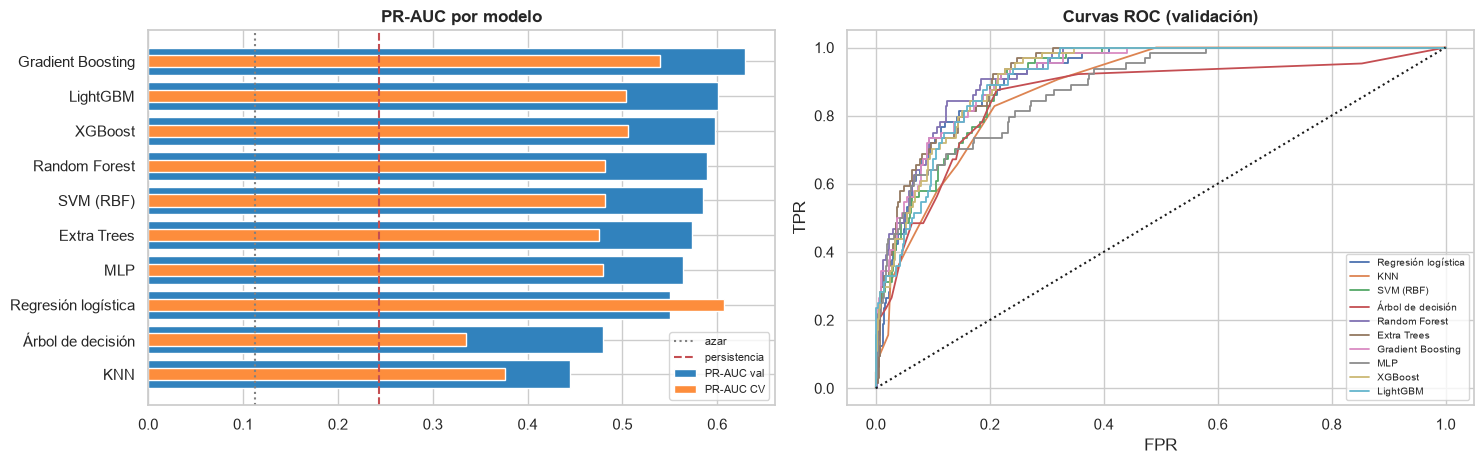

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
orden = res.sort_values("PR-AUC (val)")
ax[0].barh(orden.index, orden["PR-AUC (val)"], color="#3182bd", label="PR-AUC val"); ax[0].barh(orden.index, orden["PR-AUC (CV)"], height=.35, color="#fd8d3c", label="PR-AUC CV")
ax[0].axvline(va[Y].mean(), color="gray", ls=":", label="azar"); ax[0].axvline(base_val.loc["Base: persistencia", "PR-AUC"], color="r", ls="--", label="persistencia")
ax[0].set_title("PR-AUC por modelo"); ax[0].legend(fontsize=8)
for nombre, m in fit.items():
    fpr, tpr, _ = roc_curve(va[Y], M.probs(m, va[FEATS])); ax[1].plot(fpr, tpr, label=nombre, lw=1.3)
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].set_title("Curvas ROC (validación)"); ax[1].legend(fontsize=7)
plt.tight_layout(); guardar("09_comparacion_modelos"); plt.show()
res_show.round(4).to_csv(C.RAIZ / "reports" / "resultados_modelos_h1.csv")

### 9.1 Manejo del desbalance de clases
Se compara *sin balanceo*, *`class_weight`* y *SMOTE* (el remuestreo se hace **dentro** de cada pliegue, nunca antes de dividir) con Random Forest.

In [29]:
def rf(**kw): return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=C.SEMILLA, **kw)
variantes = {
    "RF sin balanceo": Pipeline([("clf", rf())]),
    "RF class_weight": Pipeline([("clf", rf(class_weight="balanced_subsample"))]),
    "RF + SMOTE": ImbPipeline([("smote", SMOTE(random_state=C.SEMILLA)), ("clf", rf())]),
}
res_bal, _ = M.comparar_modelos(variantes, tr[FEATS], tr[Y], va[FEATS], va[Y], tr["fecha"], gap_meses=H, verbose=False)
display(res_bal[["F1 (val)", "Precisión (val)", "Recall (val)", "PR-AUC (val)", "Brier (val)"]].round(3))

,F1 (val),Precisión (val),Recall (val),PR-AUC (val),Brier (val)
Modelo,,,,,
RF + SMOTE,0.502,0.358,0.844,0.592,0.077
RF sin balanceo,0.540,0.388,0.891,0.590,0.065
RF class_weight,0.533,0.384,0.875,0.589,0.066


## 10. Efecto del tratamiento de outliers sobre el modelo
Se repite el entrenamiento con tres versiones de las variables de lluvia y se compara en validación:
1. **ninguno** (extremos reales intactos),
2. **log1p** (comprime los extremos sin eliminarlos),
3. **winsorización IQR** (límites por punto y mes, calculados solo con *train*).

Se usan un modelo lineal (sensible a la escala y a los extremos) y uno de árboles (invariante a transformaciones monótonas).

PR-AUC (val)                          F1 (val)                    
modelo      Random Forest Regresión logística Random Forest Regresión logística
tratamiento                                                                    
log1p               0.592               0.543         0.531               0.541
ninguno             0.589               0.551         0.533               0.556
winsor              0.589               0.546         0.516               0.559

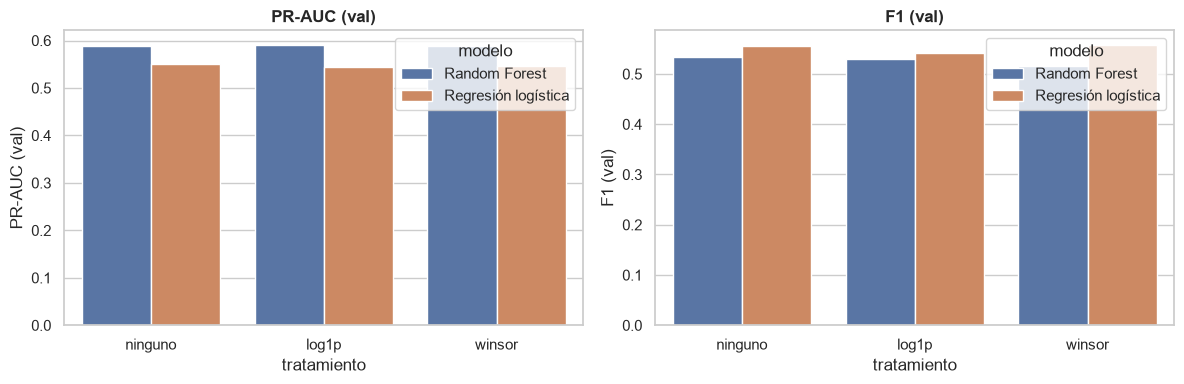

PR-AUC medio: {'log1p': 0.5674, 'ninguno': 0.5697} → tratamiento elegido para el modelo final: ninguno


In [30]:
modelos_out = {k: catalogo[k] for k in ["Regresión logística", "Random Forest"]}
ref_mask = d["fecha"] <= pd.Timestamp(C.TRAIN_FIN)
filas_o = []
for trat in ["ninguno", "log1p", "winsor"]:
    dd = F.tratar_outliers(d, trat, ref_mask)
    a, b, _ = F.particionar(dd, H, FEATS)
    r, _ = M.comparar_modelos(modelos_out, a[FEATS], a[Y], b[FEATS], b[Y], a["fecha"], gap_meses=H, verbose=False)
    for nombre, row in r.iterrows():
        filas_o.append({"tratamiento": trat, "modelo": nombre, "PR-AUC (val)": row["PR-AUC (val)"], "F1 (val)": row["F1 (val)"], "ROC-AUC (val)": row["ROC-AUC (val)"]})
exp_out = pd.DataFrame(filas_o)
display(exp_out.pivot(index="tratamiento", columns="modelo", values=["PR-AUC (val)", "F1 (val)"]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, m_ in zip(ax, ["PR-AUC (val)", "F1 (val)"]):
    sns.barplot(data=exp_out, x="tratamiento", y=m_, hue="modelo", ax=a_); a_.set_title(m_)
plt.tight_layout(); guardar("10_tratamiento_outliers"); plt.show()

# Se elige entre las opciones DESPLEGABLES (ninguno / log1p) por PR-AUC promedio en validación
punt = exp_out[exp_out["tratamiento"].isin(["ninguno", "log1p"])].groupby("tratamiento")["PR-AUC (val)"].mean()
TRAT = "log1p" if punt.get("log1p", 0) > punt.get("ninguno", 0) + 0.005 else "ninguno"   # margen para preferir lo simple
print("PR-AUC medio:", punt.round(4).to_dict(), "→ tratamiento elegido para el modelo final:", TRAT)

## 11. Ajuste de hiperparámetros
Como experimento para **h=1**, se toman los 3 mejores modelos de la sección 9 y se optimizan con `RandomizedSearchCV` sobre *train*. Esta búsqueda exploratoria usa la referencia fija 1981–2010 incluso en pliegues tempranos. La elección final por horizonte se hace en la sección 12 con evaluación temporal posterior a 2010.

In [31]:
d_mod = F.tratar_outliers(d, TRAT)
tr, va, te = F.particionar(d_mod, H, FEATS)
TOP = res.index[:3].tolist()
ESP = M.espacios_busqueda()
cv_tr = F.splits_panel(tr["fecha"], n_splits=5, gap_meses=H)
tuned, rows_t = {}, []
for nombre in TOP:
    base = clone(catalogo[nombre])
    rs = RandomizedSearchCV(base, ESP[nombre], n_iter=N_ITER, scoring="average_precision", cv=cv_tr,
                            random_state=C.SEMILLA, n_jobs=1, refit=True, error_score=np.nan)
    rs.fit(tr[FEATS], tr[Y]); mejor = rs.best_estimator_
    pcv, cub = M.oof_probs(mejor, tr[FEATS], tr[Y], tr["fecha"], 5, H)
    thr = M.mejor_umbral(tr[Y].values[cub], pcv[cub])
    met = M.metricas(va[Y], M.probs(mejor, va[FEATS]), thr)
    tuned[nombre] = {"pipe": mejor, "umbral": thr, "val": met, "cv": rs}
    rows_t.append({"Modelo": nombre, "PR-AUC val (antes)": res.loc[nombre, "PR-AUC (val)"], "PR-AUC val (después)": met["PR-AUC"],
                   "F1 val (antes)": res.loc[nombre, "F1 (val)"], "F1 val (después)": met["F1"], "mejor PR-AUC en CV": rs.best_score_,
                   "mejores parámetros": {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
    print(f"  {nombre:20s} PR-AUC val {res.loc[nombre, 'PR-AUC (val)']:.3f} → {met['PR-AUC']:.3f}")
res_tun = pd.DataFrame(rows_t).set_index("Modelo")
display(res_tun.drop(columns="mejores parámetros").round(3))
for n_, r_ in res_tun.iterrows(): print(f"• {n_}: {r_['mejores parámetros']}")

  Gradient Boosting    PR-AUC val 0.629 → 0.671


  LightGBM             PR-AUC val 0.601 → 0.636


  XGBoost              PR-AUC val 0.598 → 0.560


,PR-AUC val (antes),PR-AUC val (después),F1 val (antes),F1 val (después),mejor PR-AUC en CV
Modelo,,,,,
Gradient Boosting,0.629,0.671,0.565,0.557,0.569
LightGBM,0.601,0.636,0.521,0.571,0.571
XGBoost,0.598,0.560,0.525,0.500,0.554


• Gradient Boosting: {'learning_rate': np.float64(0.0135), 'max_depth': 4, 'n_estimators': 351, 'subsample': np.float64(0.6181)}
• LightGBM: {'colsample_bytree': np.float64(0.8059), 'learning_rate': np.float64(0.0161), 'min_child_samples': 32, 'n_estimators': 287, 'num_leaves': 19, 'subsample': np.float64(0.6931)}
• XGBoost: {'colsample_bytree': np.float64(0.7989), 'learning_rate': np.float64(0.23), 'max_depth': 5, 'min_child_weight': 9, 'n_estimators': 289, 'subsample': np.float64(0.7301)}


🏆 Mejor modelo tras el ajuste: Gradient Boosting


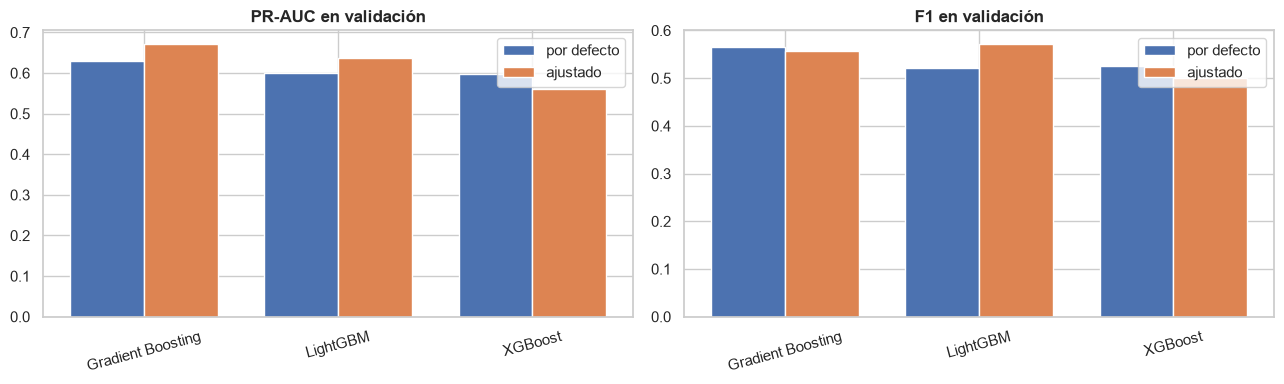

,rank_test_score,mean_test_score,std_test_score,params
18,1,0.569,0.062,"{'clf__learning_rate': 0.01351182947645082, 'c..."
6,2,0.561,0.076,"{'clf__learning_rate': 0.04345454109729477, 'c..."
11,3,0.561,0.078,"{'clf__learning_rate': 0.06792740114629246, 'c..."
12,4,0.559,0.061,"{'clf__learning_rate': 0.021930986997479973, '..."
15,5,0.558,0.068,"{'clf__learning_rate': 0.05864129169696527, 'c..."


In [32]:
# Elección del mejor: ganador por PR-AUC en validación tras el ajuste
MEJOR = max(tuned, key=lambda k: (round(tuned[k]["val"]["PR-AUC"], 3), tuned[k]["val"]["F1"]))
print("🏆 Mejor modelo tras el ajuste:", MEJOR)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(res_tun)); w = .38
for a_, (c1, c2, t) in zip(ax, [("PR-AUC val (antes)", "PR-AUC val (después)", "PR-AUC"), ("F1 val (antes)", "F1 val (después)", "F1")]):
    a_.bar(x - w / 2, res_tun[c1], w, label="por defecto"); a_.bar(x + w / 2, res_tun[c2], w, label="ajustado")
    a_.set_xticks(x); a_.set_xticklabels(res_tun.index, rotation=15); a_.set_title(f"{t} en validación"); a_.legend()
plt.tight_layout(); guardar("11_antes_despues_tuning"); plt.show()
cvr = pd.DataFrame(tuned[MEJOR]["cv"].cv_results_).sort_values("rank_test_score").head(5)
display(cvr[["rank_test_score", "mean_test_score", "std_test_score", "params"]].round(4))
res_tun.to_csv(C.RAIZ / "reports" / "resultados_tuning_h1.csv")

## 12. Evaluación final en el conjunto de prueba (2019 →)
Cada horizonte compara sus propios candidatos con pliegues de dos años entre 2011 y 2018. El periodo de referencia SPI/climatología (1981–2010) ya está disponible al comenzar esos pliegues; además, se excluyen del entrenamiento las etiquetas t+h aún no conocidas. Se eligen modelo y umbral con predicciones *out-of-fold* y después se reentrena con train + validación. h=3 incluye una referencia climatológica porque el SPI-3 objetivo depende de tres meses de lluvia futura. Las métricas 2019–2025 ya se han inspeccionado en iteraciones previas: se presentan como evaluación histórica y una mejora definitiva requiere confirmación prospectiva.

In [33]:
finales, resumen_cv = {}, {}
for h in C.HORIZONTES:
    trat_h = TRAT if h == 1 else "ninguno"
    opciones = P.candidatos_horizonte(d, h, FEATS, modelo_h1=tuned[MEJOR]["pipe"] if h == 1 else None)
    tabla_cv = P.comparar_candidatos_post_referencia(d, h, opciones, trat_h, filtro_comun=FEATS)
    elegido = P.elegir_candidato(tabla_cv, h)
    pipe_h, feats_h = opciones[elegido]
    finales[h] = P.entrenar_final(d, h, pipe_h, feats_h, trat_h)
    finales[h]["nombre"] = elegido
    resumen_cv[h] = tabla_cv
    print(f"h={h}: elegido {elegido} | CV F1={tabla_cv.loc[elegido, 'F1']:.3f}, PR-AUC={tabla_cv.loc[elegido, 'PR-AUC']:.3f}")
    display(tabla_cv[["F1", "PR-AUC", "Precisión", "Recall", "umbral", "fraccion_alertas"]].round(3))
    tabla_cv.round(4).to_csv(C.RAIZ / "reports" / f"seleccion_post_ref_h{h}.csv")
fin1 = finales[1]
tr_f, va_f, te_f = F.particionar(d_mod, 1, FEATS)
tv_f = pd.concat([tr_f, va_f])
base_test = M.lineas_base(tv_f, te_f, Y, Y)
fila_modelo = pd.DataFrame([{"Modelo": f"{fin1['nombre']} (final)", **fin1["metricas_test"]}]).set_index("Modelo")
tabla_test = pd.concat([fila_modelo, base_test])
display(tabla_test.round(3))
print(f"Umbral de decisión: {fin1['umbral']:.3f} | train+val: {fin1['n_train']} filas | test: {fin1['n_test']} filas | prevalencia test: {te_f[Y].mean()*100:.1f}%")
tabla_test.round(4).to_csv(C.RAIZ / "reports" / "resultados_test_h1.csv")

h=1: elegido Gradient Boosting ajustado | CV F1=0.616, PR-AUC=0.681


,F1,PR-AUC,Precisión,Recall,umbral,fraccion_alertas
Modelo,,,,,,
Regresión logística,0.623,0.607,0.567,0.692,0.720,0.169
Gradient Boosting,0.620,0.644,0.539,0.731,0.259,0.188
Gradient Boosting ajustado,0.616,0.681,0.575,0.663,0.347,0.160
LightGBM regulado,0.609,0.606,0.532,0.712,0.273,0.185
XGBoost,0.606,0.625,0.606,0.606,0.623,0.138
Random Forest,0.604,0.596,0.622,0.587,0.469,0.130
LightGBM,0.599,0.644,0.553,0.654,0.252,0.164
Climatología,0.317,0.232,0.317,0.317,0.211,0.138


h=2: elegido LightGBM regulado | CV F1=0.520, PR-AUC=0.427


,F1,PR-AUC,Precisión,Recall,umbral,fraccion_alertas
Modelo,,,,,,
LightGBM regulado,0.520,0.427,0.445,0.625,0.292,0.198
Gradient Boosting,0.506,0.441,0.425,0.625,0.275,0.208
LightGBM,0.502,0.439,0.374,0.760,0.116,0.287
XGBoost,0.500,0.377,0.385,0.712,0.376,0.261
Random Forest,0.486,0.374,0.378,0.683,0.316,0.255
Regresión logística,0.464,0.443,0.384,0.587,0.706,0.216
Climatología,0.317,0.232,0.317,0.317,0.211,0.141


h=3: elegido Climatología | CV F1=0.322, PR-AUC=0.235


,F1,PR-AUC,Precisión,Recall,umbral,fraccion_alertas
Modelo,,,,,,
Climatología,0.322,0.235,0.201,0.798,0.149,0.572
LightGBM,0.300,0.230,0.255,0.365,0.173,0.207
LightGBM regulado,0.294,0.222,0.223,0.433,0.182,0.281
Random Forest,0.291,0.202,0.202,0.519,0.221,0.371
XGBoost,0.288,0.241,0.288,0.288,0.490,0.144
Gradient Boosting,0.276,0.206,0.210,0.404,0.175,0.278
Regresión logística,0.258,0.185,0.186,0.423,0.537,0.329


,F1,Precisión,Recall,Bal.Acc,Brier,PR-AUC,ROC-AUC
Modelo,,,,,,,
Gradient Boosting ajustado (final),0.663,0.594,0.750,0.838,0.066,0.603,0.929
Base: siempre 'no sequía',0.000,0.000,0.000,0.500,0.127,0.127,0.500
Base: persistencia,0.578,0.585,0.571,0.756,0.105,0.389,0.756
Base: climatología,0.293,0.191,0.631,0.622,0.107,0.219,0.634


Umbral de decisión: 0.347 | train+val: 3344 filas | test: 664 filas | prevalencia test: 12.7%


In [34]:
# Intervalo de confianza por bootstrap sobre FECHAS (preserva la correlación entre puntos del mismo mes)
def ic_bootstrap(fechas, y, p, thr, n=300, seed=0):
    rng = np.random.default_rng(seed)
    df_ = pd.DataFrame({"f": np.asarray(fechas), "y": np.asarray(y), "p": np.asarray(p)})
    grupos = [g for _, g in df_.groupby("f")]; out = []
    for _ in range(n):
        s = pd.concat([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])
        if s["y"].nunique() < 2: continue
        m = M.metricas(s["y"], s["p"], thr); out.append((m["F1"], m["PR-AUC"], m["ROC-AUC"]))
    return pd.DataFrame(np.percentile(np.array(out), [2.5, 50, 97.5], axis=0), index=["2.5 %", "mediana", "97.5 %"], columns=["F1", "PR-AUC", "ROC-AUC"])
ic = ic_bootstrap(te_f["fecha"].values, fin1["y_test"], fin1["p_test"], fin1["umbral"])
print("IC 95 % (bootstrap por fechas) en test:"); display(ic.round(3))

IC 95 % (bootstrap por fechas) en test:


,F1,PR-AUC,ROC-AUC
2.5 %,0.527,0.435,0.894
mediana,0.665,0.616,0.930
97.5 %,0.755,0.805,0.956


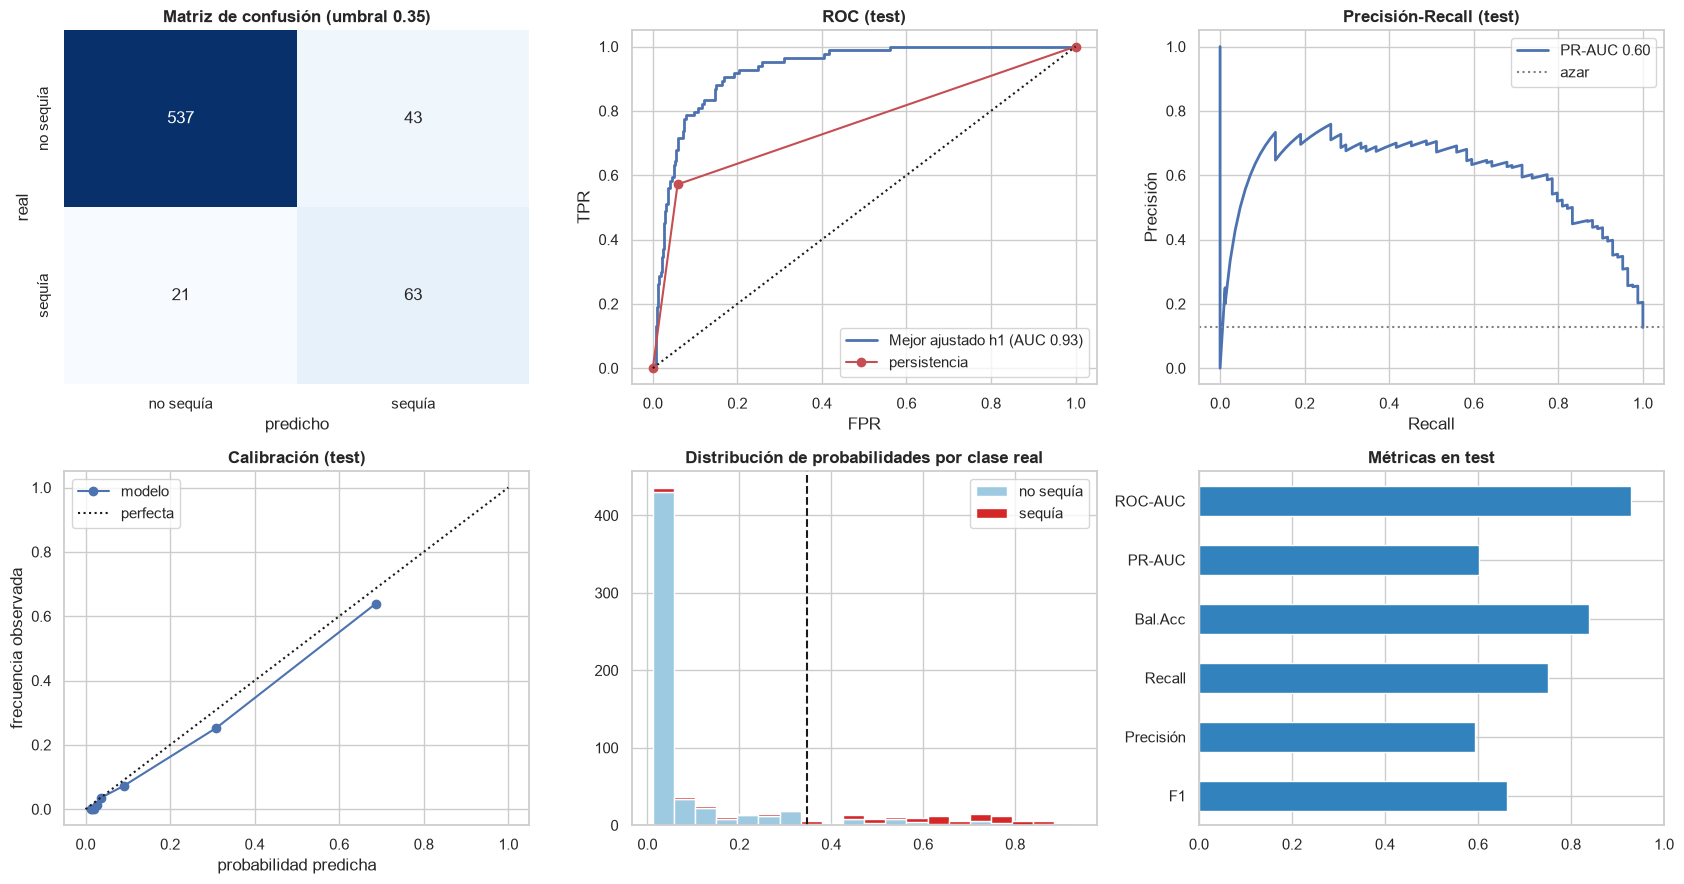

In [35]:
y_t, p_t, thr = fin1["y_test"].astype(int), fin1["p_test"], fin1["umbral"]
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
cm = M.matriz_confusion(y_t, p_t, thr)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0, 0], xticklabels=["no sequía", "sequía"], yticklabels=["no sequía", "sequía"])
ax[0, 0].set_xlabel("predicho"); ax[0, 0].set_ylabel("real"); ax[0, 0].set_title(f"Matriz de confusión (umbral {thr:.2f})")
fpr, tpr, _ = roc_curve(y_t, p_t); ax[0, 1].plot(fpr, tpr, lw=2, label=f"{fin1['nombre']} (AUC {fin1['metricas_test']['ROC-AUC']:.2f})")
fp_, tp_, _ = roc_curve(y_t, te_f["sequia_actual"]); ax[0, 1].plot(fp_, tp_, "o-", color="r", label="persistencia")
ax[0, 1].plot([0, 1], [0, 1], "k:"); ax[0, 1].set_title("ROC (test)"); ax[0, 1].legend(); ax[0, 1].set_xlabel("FPR"); ax[0, 1].set_ylabel("TPR")
pr, rc, _ = precision_recall_curve(y_t, p_t); ax[0, 2].plot(rc, pr, lw=2, label=f"PR-AUC {fin1['metricas_test']['PR-AUC']:.2f}")
ax[0, 2].axhline(y_t.mean(), color="gray", ls=":", label="azar"); ax[0, 2].set_title("Precisión-Recall (test)"); ax[0, 2].legend(); ax[0, 2].set_xlabel("Recall"); ax[0, 2].set_ylabel("Precisión")
fr, mp = calibration_curve(y_t, p_t, n_bins=8, strategy="quantile"); ax[1, 0].plot(mp, fr, "o-", label="modelo"); ax[1, 0].plot([0, 1], [0, 1], "k:", label="perfecta")
ax[1, 0].set_title("Calibración (test)"); ax[1, 0].set_xlabel("probabilidad predicha"); ax[1, 0].set_ylabel("frecuencia observada"); ax[1, 0].legend()
ax[1, 1].hist([p_t[y_t == 0], p_t[y_t == 1]], bins=20, stacked=True, label=["no sequía", "sequía"], color=["#9ecae1", "#d62728"]); ax[1, 1].axvline(thr, color="k", ls="--")
ax[1, 1].set_title("Distribución de probabilidades por clase real"); ax[1, 1].legend()
imp_g = pd.Series(fin1["metricas_test"]).drop(["Brier"]); imp_g.plot.barh(ax=ax[1, 2], color="#3182bd"); ax[1, 2].set_title("Métricas en test"); ax[1, 2].set_xlim(0, 1)
plt.tight_layout(); guardar("12_evaluacion_test"); plt.show()

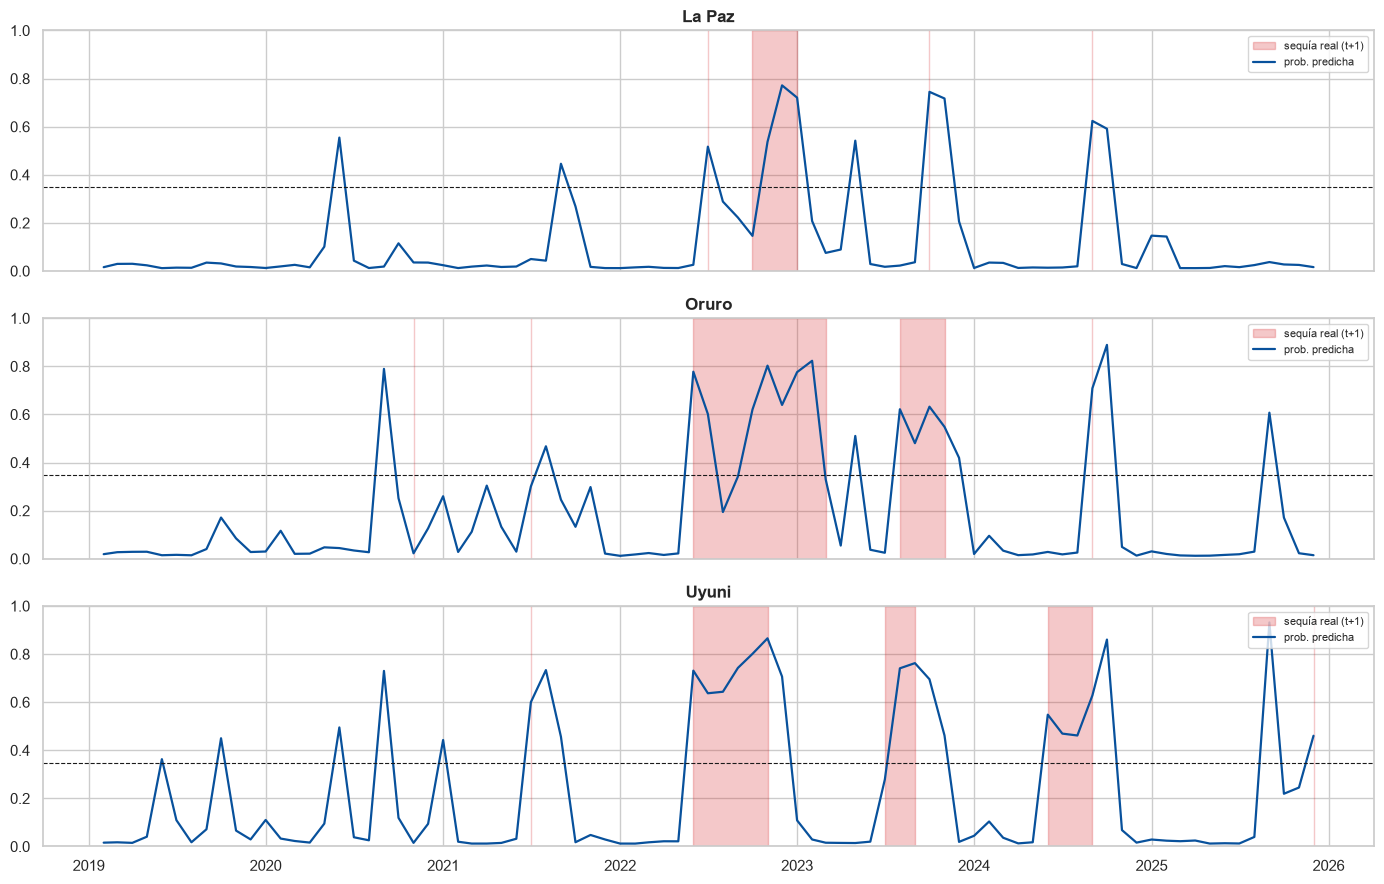

In [36]:
te1 = d_mod.loc[fin1["test_idx"]].copy(); te1["p"] = p_t; te1["pred"] = (p_t >= thr).astype(int)
sel = [p for p in ["La Paz", "Oruro", "Uyuni"] if p in C.PUNTOS][:3]
fig, axes = plt.subplots(len(sel), 1, figsize=(14, 3 * len(sel)), sharex=True)
for ax, p in zip(np.atleast_1d(axes), sel):
    g = te1[te1["punto"] == p].sort_values("fecha"); x_obj = g["fecha"] + pd.DateOffset(months=1)
    ax.fill_between(x_obj, 0, 1, where=g[Y].values == 1, color="#d62728", alpha=.25, step="mid", label="sequía real (t+1)")
    ax.plot(x_obj, g["p"], color="#08519c", lw=1.6, label="prob. predicha"); ax.axhline(thr, color="k", ls="--", lw=.8)
    ax.set_ylim(0, 1); ax.set_title(p); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); guardar("12_serie_test"); plt.show()

## 13. Desempeño según el horizonte de predicción (1, 2 y 3 meses)

,Modelo,F1,PR-AUC,ROC-AUC,Recall,Precisión,F1 persistencia,PR-AUC persistencia,F1 climatología,prevalencia test
h (meses),,,,,,,,,,
1,Gradient Boosting ajustado,0.663,0.603,0.929,0.750,0.594,0.578,0.389,0.293,0.127
2,LightGBM regulado,0.417,0.331,0.828,0.524,0.346,0.386,0.228,0.293,0.128
3,Climatología,0.279,0.209,0.635,0.361,0.227,0.291,0.176,0.276,0.128


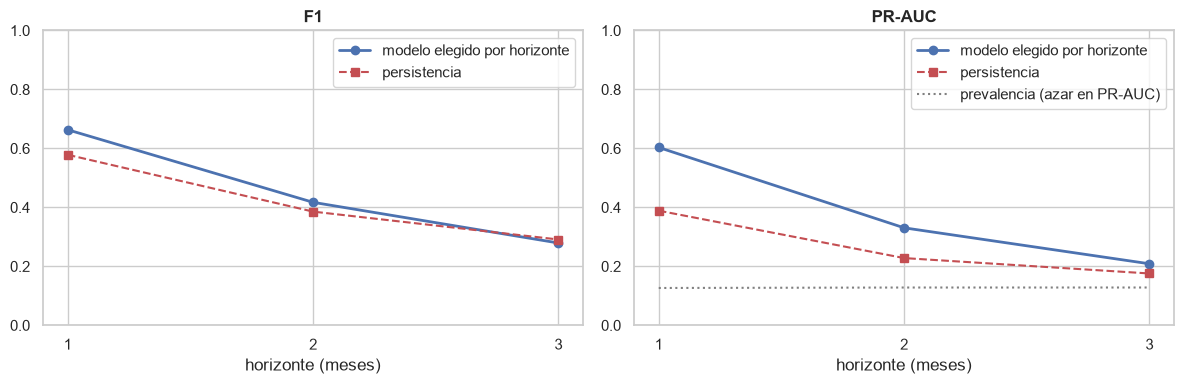

h=3 usa una referencia climatológica si los modelos no la superan en validación. Una ventaja en PR-AUC no garantiza mejor F1 ni utilidad práctica.


In [37]:
rows_h = []
for h in C.HORIZONTES:
    f = finales[h]; Yh = f"y_h{h}"
    a, b, c = F.particionar(d_mod, h, f["features"]); bt = M.lineas_base(pd.concat([a, b]), c, Yh, Yh)
    rows_h.append({"h (meses)": h, "Modelo": f["nombre"], "F1": f["metricas_test"]["F1"], "PR-AUC": f["metricas_test"]["PR-AUC"], "ROC-AUC": f["metricas_test"]["ROC-AUC"],
                   "Recall": f["metricas_test"]["Recall"], "Precisión": f["metricas_test"]["Precisión"],
                   "F1 persistencia": bt.loc["Base: persistencia", "F1"], "PR-AUC persistencia": bt.loc["Base: persistencia", "PR-AUC"],
                   "F1 climatología": bt.loc["Base: climatología", "F1"],
                   "prevalencia test": c[Yh].mean()})
res_h = pd.DataFrame(rows_h).set_index("h (meses)"); display(res_h.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (m_, b_) in zip(ax, [("F1", "F1 persistencia"), ("PR-AUC", "PR-AUC persistencia")]):
    a_.plot(res_h.index, res_h[m_], "o-", lw=2, label="modelo elegido por horizonte"); a_.plot(res_h.index, res_h[b_], "s--", color="r", label="persistencia")
    a_.plot(res_h.index, res_h["prevalencia test"], ":", color="gray", label="prevalencia (azar en PR-AUC)") if m_ == "PR-AUC" else None
    a_.set_xticks(res_h.index); a_.set_xlabel("horizonte (meses)"); a_.set_title(m_); a_.legend(); a_.set_ylim(0, 1)
plt.tight_layout(); guardar("13_horizontes"); plt.show()
res_h.round(4).to_csv(C.RAIZ / "reports" / "resultados_horizontes.csv")
print("h=3 usa una referencia climatológica si los modelos no la superan en validación. Una ventaja en PR-AUC no garantiza mejor F1 ni utilidad práctica.")

## 14. Análisis de errores (h = 1, test)
Por punto, por mes calendario del mes objetivo y por fase de ENSO (ONI con rezago 2, la información disponible al predecir).

,n,sequías reales,precisión,recall,F1
punto,,,,,
Challapata,83.0,12.0,0.69,0.75,0.72
Charaña,83.0,6.0,0.83,0.83,0.83
Copacabana,83.0,8.0,0.45,0.62,0.53
La Paz,83.0,7.0,0.55,0.86,0.67
Oruro,83.0,17.0,0.67,0.71,0.69
Patacamaya,83.0,8.0,0.50,0.50,0.50
Potosí,83.0,11.0,0.62,0.73,0.67
Uyuni,83.0,15.0,0.54,0.93,0.68


,n,sequías reales,precisión,recall,F1
fase_enso,,,,,
El Niño,208.0,21.0,0.61,0.81,0.69
La Niña,216.0,46.0,0.85,0.76,0.80
Neutro,240.0,17.0,0.30,0.65,0.41


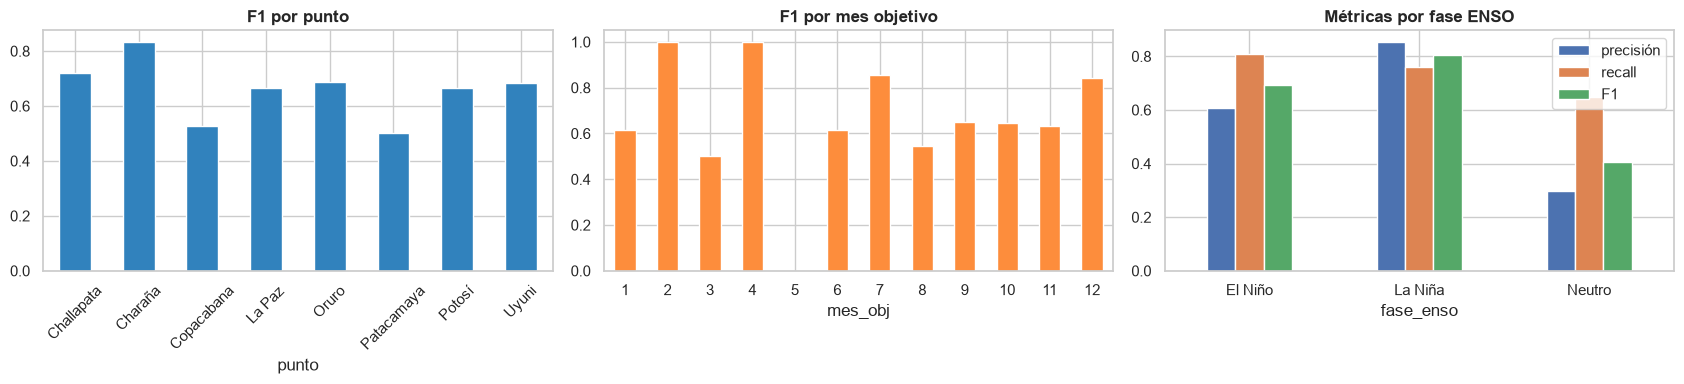

Falsos negativos más graves (sequía real no detectada):


,punto,fecha,p,spi3,lluvia
2637,Oruro,2020-10-01,0.023,-0.379,23.81
522,Challapata,2024-07-01,0.031,-0.089,0.55
3222,Patacamaya,2024-07-01,0.032,1.009,0.39
3185,Patacamaya,2021-06-01,0.044,-0.222,1.42
3762,Potosí,2024-07-01,0.057,-0.408,1.09
1581,Copacabana,2022-10-01,0.067,-0.570,12.01
1618,Copacabana,2025-11-01,0.100,-0.140,26.85
3211,Patacamaya,2023-08-01,0.109,-1.108,0.40


Falsos positivos más confiados (falsa alarma):


,punto,fecha,p,spi3,lluvia
4315,Uyuni,2025-08-01,0.931,1.742,0.04
3775,Potosí,2025-08-01,0.909,3.000,1.35
2684,Oruro,2024-09-01,0.889,-2.702,2.40
4304,Uyuni,2024-09-01,0.860,-1.348,3.87
2635,Oruro,2020-08-01,0.789,1.562,1.41
524,Challapata,2024-09-01,0.783,-1.620,6.40
3752,Potosí,2023-09-01,0.769,-2.667,1.11
1593,Copacabana,2023-10-01,0.735,-1.729,21.08


In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score
te1["mes_obj"] = (te1["fecha"] + pd.DateOffset(months=1)).dt.month
te1["fase_enso"] = np.where(te1["oni_l2"] >= 0.5, "El Niño", np.where(te1["oni_l2"] <= -0.5, "La Niña", "Neutro"))
def resumen(g):
    y, p = g[Y].astype(int), g["pred"]
    return pd.Series({"n": len(g), "sequías reales": int(y.sum()), "precisión": precision_score(y, p, zero_division=0),
                      "recall": recall_score(y, p, zero_division=0), "F1": f1_score(y, p, zero_division=0)})
por_punto = te1.groupby("punto").apply(resumen); por_mes = te1.groupby("mes_obj").apply(resumen); por_fase = te1.groupby("fase_enso").apply(resumen)
display(por_punto.round(2)); display(por_fase.round(2))
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
por_punto["F1"].plot.bar(ax=ax[0], color="#3182bd"); ax[0].set_title("F1 por punto"); ax[0].tick_params(axis="x", rotation=45)
por_mes["F1"].plot.bar(ax=ax[1], color="#fd8d3c"); ax[1].set_title("F1 por mes objetivo"); ax[1].tick_params(axis="x", rotation=0)
por_fase[["precisión", "recall", "F1"]].plot.bar(ax=ax[2]); ax[2].set_title("Métricas por fase ENSO"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar("14_errores"); plt.show()
fn = te1[(te1[Y] == 1) & (te1["pred"] == 0)].sort_values("p")[["punto", "fecha", "p", "spi3", "lluvia"]].head(8)
fp = te1[(te1[Y] == 0) & (te1["pred"] == 1)].sort_values("p", ascending=False)[["punto", "fecha", "p", "spi3", "lluvia"]].head(8)
print("Falsos negativos más graves (sequía real no detectada):"); display(fn)
print("Falsos positivos más confiados (falsa alarma):"); display(fp)

## 15. Interpretabilidad y ablación
### 15.1 Importancia por permutación y SHAP

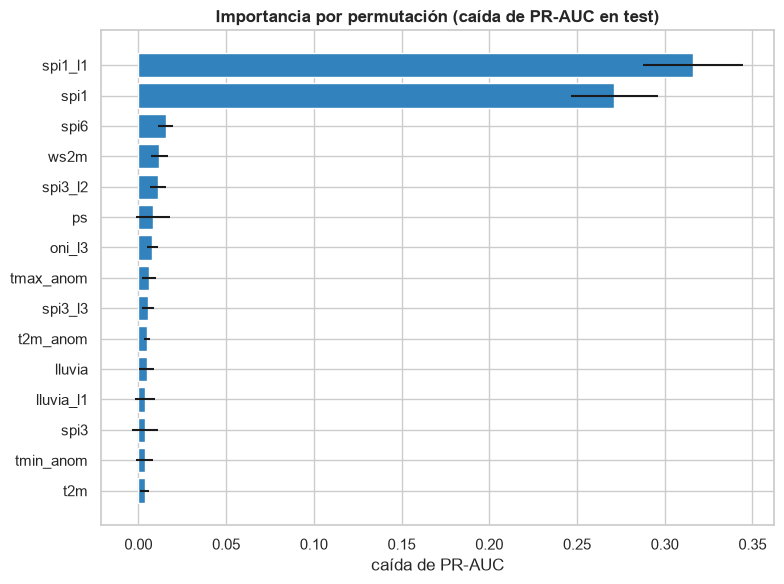

In [39]:
pim = permutation_importance(fin1["pipeline"], te1[FEATS], te1[Y], scoring="average_precision", n_repeats=20, random_state=C.SEMILLA, n_jobs=1)
imp = pd.DataFrame({"media": pim.importances_mean, "std": pim.importances_std}, index=FEATS).sort_values("media")
top = imp.tail(15)
plt.figure(figsize=(8, 6)); plt.barh(top.index, top["media"], xerr=top["std"], color="#3182bd")
plt.title("Importancia por permutación (caída de PR-AUC en test)"); plt.xlabel("caída de PR-AUC"); plt.tight_layout(); guardar("15_importancia_permutacion"); plt.show()

C:\Users\ALEXANDRA\Desktop\proyAnalisis\proyecto_sequia\proyecto_sequia\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


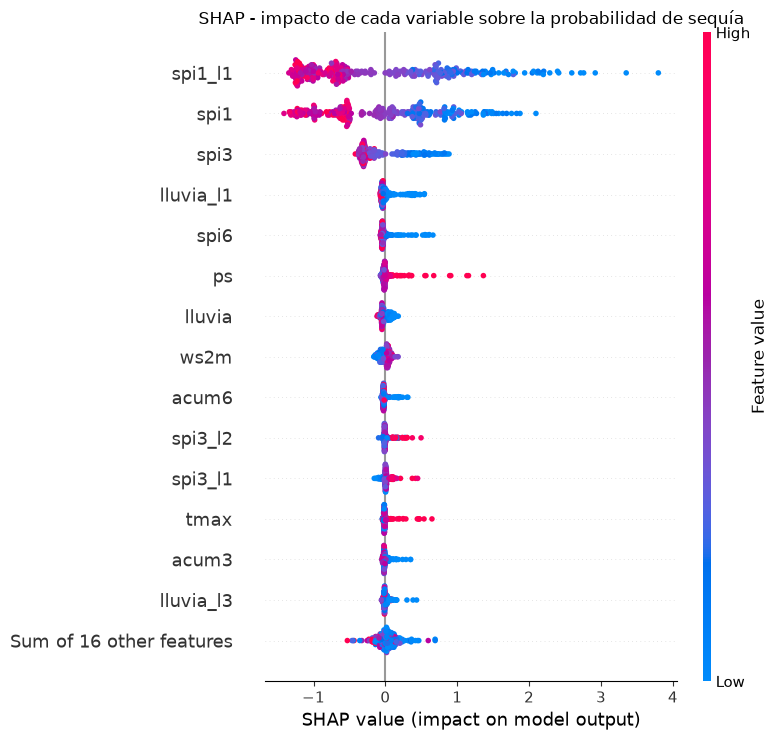

In [40]:
try:
    import shap
    pipe_f = fin1["pipeline"]; clf = pipe_f.named_steps["clf"]
    Xs = te1[FEATS].sample(n=min(300, len(te1)), random_state=C.SEMILLA)
    if "scaler" in pipe_f.named_steps:
        Xs = pd.DataFrame(pipe_f[:-1].transform(Xs), columns=FEATS, index=Xs.index)
    expl = shap.TreeExplainer(clf)
    sv = expl(Xs)
    if getattr(sv, "values", None) is not None and sv.values.ndim == 3: sv = sv[:, :, 1]
    plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.title("SHAP - impacto de cada variable sobre la probabilidad de sequía")
    plt.tight_layout(); guardar("15_shap"); plt.show()
except Exception as e:
    print("SHAP no disponible para este modelo/entorno:", type(e).__name__, str(e)[:120])

### 15.2 Ablación: ¿qué variables aportan de verdad?
Se reentrena el modelo quitando grupos de variables y se mide en **validación** (no en test, para no “espiar” el conjunto final).

,n variables,PR-AUC (val),F1 (val)
Variante,,,
Completo,30,0.671,0.557
Sin ONI,28,0.664,0.539
Sin altitud,29,0.666,0.548
"Sin lluvia/SPI (solo temp., humedad, ONI...)",16,0.260,0.284
Solo lluvia/SPI + estacionalidad,16,0.646,0.565
Solo ONI + estacionalidad,4,0.150,0.203


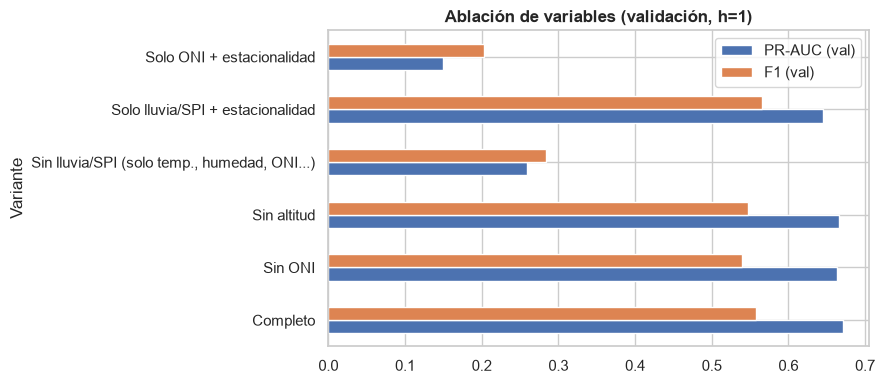

In [41]:
G_LLUVIA = F.COLS_LLUVIA + ["spi1", "spi3", "spi6", "spi1_l1", "spi3_l1", "spi3_l2", "spi3_l3"]
G_OTRAS = ["t2m", "tmax", "tmin", "rh2m", "ws2m", "ps", "rad", "t2m_anom", "tmin_anom", "tmax_anom", "rh2m_anom"]
variantes_f = {
    "Completo": FEATS,
    "Sin ONI": F.lista_features(con_oni=False),
    "Sin altitud": F.lista_features(con_estaticas=False),
    "Sin lluvia/SPI (solo temp., humedad, ONI...)": [f for f in FEATS if f not in G_LLUVIA],
    "Solo lluvia/SPI + estacionalidad": G_LLUVIA + ["mes_sin", "mes_cos"],
    "Solo ONI + estacionalidad": F.FEATURES_ONI + ["mes_sin", "mes_cos"],
}
rows_a = []
for nombre, fs in variantes_f.items():
    a, b, _ = F.particionar(d_mod, H, fs)
    r, _ = M.comparar_modelos({nombre: clone(fin1["pipeline"])}, a[fs], a[Y], b[fs], b[Y], a["fecha"], gap_meses=H, verbose=False)
    rows_a.append({"Variante": nombre, "n variables": len(fs), "PR-AUC (val)": r["PR-AUC (val)"].iloc[0], "F1 (val)": r["F1 (val)"].iloc[0]})
abl = pd.DataFrame(rows_a).set_index("Variante"); display(abl.round(3))
abl[["PR-AUC (val)", "F1 (val)"]].plot.barh(figsize=(9, 4)); plt.title("Ablación de variables (validación, h=1)"); plt.tight_layout(); guardar("15_ablacion"); plt.show()

### 15.3 ¿Ayudan los rezagos largos a h=3?
Se prueban rezagos de 6 y 12 meses de lluvia, SPI-3 y ONI, además de la tendencia reciente del ONI. Son variables conocidas al final del mes base. Se compara su PR-AUC en validación 2013–2018 con las variables actuales; si no mejoran, no se incorporan al modelo final.

In [42]:
d_largo = d.sort_values(["punto", "fecha"]).reset_index(drop=True).copy()
for lag in (6, 12):
    d_largo[f"spi3_l{lag}"] = d_largo.groupby("punto")["spi3"].shift(lag)
d_largo["lluvia_l12"] = d_largo.groupby("punto")["lluvia"].shift(12)
d_largo["acum12"] = d_largo.groupby("punto")["lluvia"].transform(lambda s: s.rolling(12, min_periods=12).sum())
oni_serie = oni.set_index("fecha")["oni"]
for lag in (6, 12):
    d_largo[f"oni_l{lag}"] = (d_largo["fecha"] - pd.DateOffset(months=lag)).map(oni_serie)
d_largo["oni_tendencia"] = d_largo["oni_l2"] - d_largo["oni_l6"]
FEATS_LARGAS = FEATS + ["spi3_l6", "spi3_l12", "lluvia_l12", "acum12", "oni_l6", "oni_l12", "oni_tendencia"]
cat_largo = M.catalogo_modelos()
lgb_largo = clone(cat_largo["LightGBM"]).set_params(clf__num_leaves=7, clf__min_child_samples=50, clf__reg_lambda=2.0)
filas_largas = []
for conjunto, fs in [("actual", FEATS), ("rezagos largos", FEATS_LARGAS)]:
    a, b, _ = F.particionar(d_largo, 3, fs)
    r, _ = M.comparar_modelos({"Random Forest": cat_largo["Random Forest"], "LightGBM regulado": lgb_largo},
                             a[fs], a["y_h3"], b[fs], b["y_h3"], a["fecha"], gap_meses=3, verbose=False)
    for nombre, fila in r.iterrows():
        filas_largas.append({"variables": conjunto, "modelo": nombre, "PR-AUC val": fila["PR-AUC (val)"], "F1 val": fila["F1 (val)"]})
tabla_largas = pd.DataFrame(filas_largas); display(tabla_largas.round(3))
tabla_largas.to_csv(C.RAIZ / "reports" / "variables_largas_h3.csv", index=False)


,variables,modelo,PR-AUC val,F1 val
0,actual,LightGBM regulado,0.222,0.208
1,actual,Random Forest,0.211,0.208
2,rezagos largos,Random Forest,0.184,0.208
3,rezagos largos,LightGBM regulado,0.177,0.208


## 16. Caso histórico: crisis hídrica de La Paz y El Alto (2015-2016)
Para contar una historia honesta se usa un modelo entrenado **solo con datos hasta 2012** (el periodo 2015-2016 queda **fuera** del entrenamiento). Se mira si la probabilidad de sequía anticipó los meses secos observados en el SPI-3. No se afirma nada por adelantado: el gráfico y la tabla muestran lo que el modelo realmente hizo, **incluidos los fallos**.

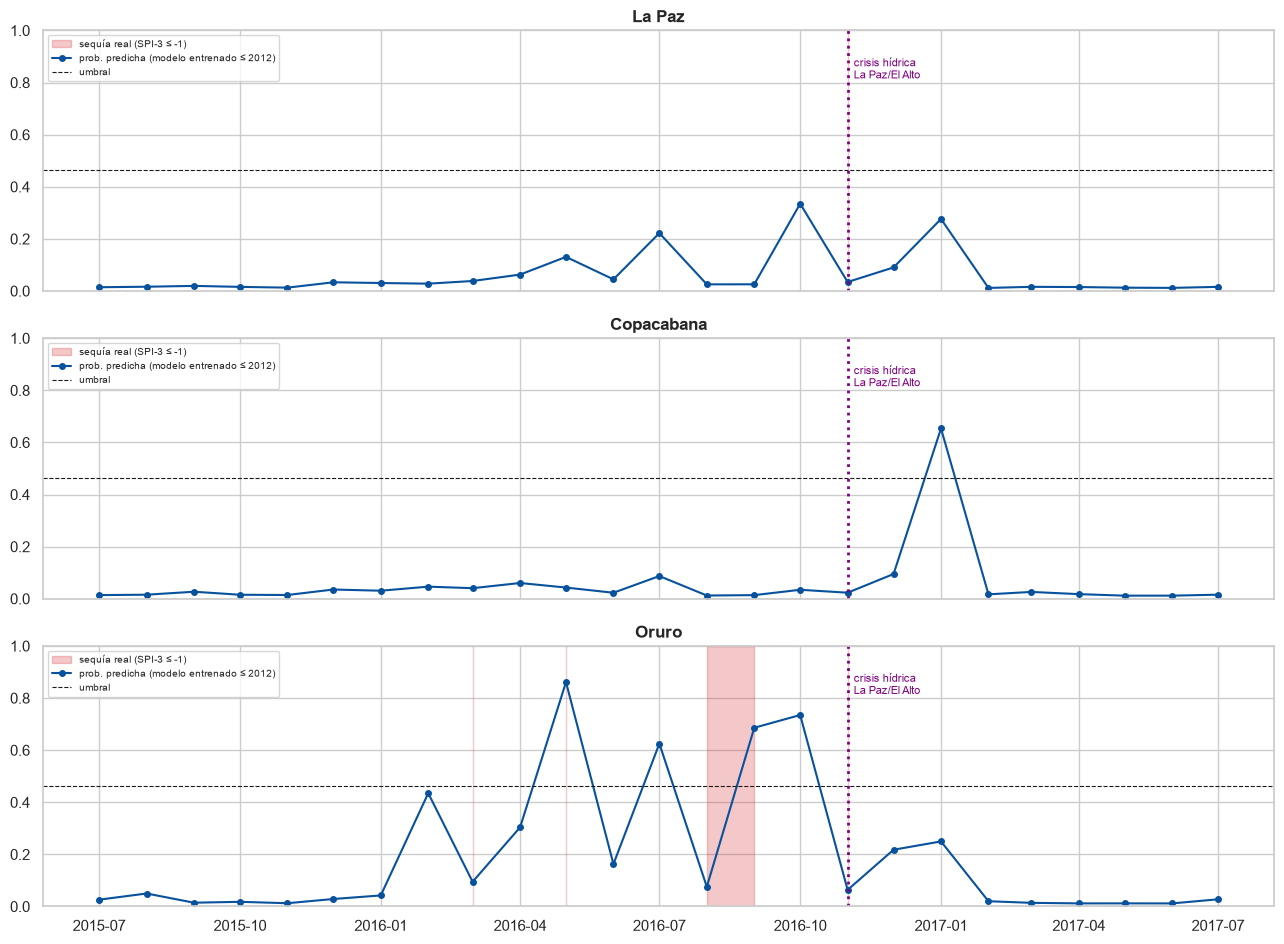

,meses,sequías reales,alertas,aciertos (alerta y sequía)
punto,,,,
Challapata,25,4,2,1
Charaña,25,0,1,0
Copacabana,25,0,1,0
La Paz,25,1,0,0
Oruro,25,5,4,2
Patacamaya,25,1,1,1
Potosí,25,9,6,5
Uyuni,25,4,5,4


In [43]:
pipe_hist = clone(fin1["pipeline"]).fit(tr[FEATS], tr[Y])
pcv_h, cub_h = M.oof_probs(fin1["pipeline"], tr[FEATS], tr[Y], tr["fecha"], cv=F.splits_post_referencia(tr["fecha"], H))
thr_h = M.mejor_umbral(tr[Y].values[cub_h], pcv_h[cub_h])
sub = d_mod[(d_mod["fecha"] >= "2015-06-01") & (d_mod["fecha"] <= "2017-06-01")].dropna(subset=FEATS + [Y]).copy()
sub["p"] = M.probs(pipe_hist, sub[FEATS]); sub["f_obj"] = sub["fecha"] + pd.DateOffset(months=1)
casos = [p for p in ["La Paz", "Copacabana", "Oruro"] if p in C.PUNTOS]
fig, axes = plt.subplots(len(casos), 1, figsize=(13, 3.2 * len(casos)), sharex=True)
for ax, p in zip(np.atleast_1d(axes), casos):
    g = sub[sub["punto"] == p].sort_values("fecha")
    ax.fill_between(g["f_obj"], 0, 1, where=g[Y].values == 1, color="#d62728", alpha=.25, step="mid", label="sequía real (SPI-3 ≤ -1)")
    ax.plot(g["f_obj"], g["p"], "o-", color="#08519c", ms=4, label="prob. predicha (modelo entrenado ≤ 2012)"); ax.axhline(thr_h, color="k", ls="--", lw=.8, label="umbral")
    ax.axvline(pd.Timestamp("2016-11-01"), color="purple", ls=":", lw=2); ax.text(pd.Timestamp("2016-11-05"), .9, "crisis hídrica\nLa Paz/El Alto", color="purple", fontsize=8, va="top")
    ax.set_ylim(0, 1); ax.set_title(p); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); guardar("16_caso_2016"); plt.show()
sub["alerta"] = sub["p"] >= thr_h; sub["sequía real"] = sub[Y] == 1
tab16 = sub.groupby("punto").apply(lambda g: pd.Series({"meses": len(g), "sequías reales": int(g["sequía real"].sum()), "alertas": int(g["alerta"].sum()),
                                                       "aciertos (alerta y sequía)": int((g["alerta"] & g["sequía real"]).sum())}))
display(tab16)

## 17. Opción (a) vs (b): ¿solo temporada lluviosa o todos los meses?
En el Altiplano, entre mayo y septiembre casi no llueve y el SPI-3 se vuelve inestable (acumulados ≈ 0). Se compara entrenar con **todos los meses** frente a entrenar **solo con meses objetivo de octubre a marzo**, y se evalúa siempre solo en la temporada lluviosa de la validación, que es donde la sequía importa para la agricultura.

In [44]:
LLUV = [10, 11, 12, 1, 2, 3]
def mes_obj(x, h=H): return (x["fecha"] + pd.DateOffset(months=h)).dt.month
tr_l, va_l = tr[mes_obj(tr).isin(LLUV)], va[mes_obj(va).isin(LLUV)]
rows_l = []
for nombre, base_tr in [("(b) entrenado con todos los meses", tr), ("(a) entrenado solo con temporada lluviosa", tr_l)]:
    m = clone(fin1["pipeline"]).fit(base_tr[FEATS], base_tr[Y])
    pcv, cub = M.oof_probs(fin1["pipeline"], base_tr[FEATS], base_tr[Y], base_tr["fecha"], cv=F.splits_post_referencia(base_tr["fecha"], H))
    thr_l = M.mejor_umbral(base_tr[Y].values[cub], pcv[cub])
    met = M.metricas(va_l[Y], M.probs(m, va_l[FEATS]), thr_l)
    rows_l.append({"Estrategia": nombre, "filas train": len(base_tr), **{k: met[k] for k in ["F1", "Precisión", "Recall", "PR-AUC", "ROC-AUC"]}})
cmp17 = pd.DataFrame(rows_l).set_index("Estrategia"); display(cmp17.round(3))
print(f"Evaluación solo en temporada lluviosa de validación: {len(va_l)} filas, {va_l[Y].mean()*100:.1f}% sequía")

,filas train,F1,Precisión,Recall,PR-AUC,ROC-AUC
Estrategia,,,,,,
(b) entrenado con todos los meses,2776,0.486,0.5,0.474,0.459,0.918
(a) entrenado solo con temporada lluviosa,1384,0.296,0.5,0.211,0.437,0.930


Evaluación solo en temporada lluviosa de validación: 280 filas, 6.8% sequía


## 18. Guardado para el despliegue
Se empaqueta lo necesario para predecir en producción (`models/artefacto_sequia.joblib`): los modelos de h = 1, 2, 3 con su umbral y lista de variables, los **parámetros gamma del SPI** y la **climatología** de referencia. La app y la API cargan este archivo.

In [45]:
assert TRAT in ("ninguno", "log1p"), "El despliegue solo soporta tratamiento 'ninguno' o 'log1p'"
art = P.armar_artefacto({"spi_params": params, "climatologia": clim}, finales, "por horizonte")
ruta = PR.guardar_artefacto(art)
d.drop(columns=[c for c in ["f_iqr", "f_mad", "flag_if", "votos", "seq"] if c in d.columns]).to_csv(C.DATA_PROC / "dataset_modelado.csv", index=False)
print("Artefacto guardado en:", ruta, f"({ruta.stat().st_size/1e6:.1f} MB) | versión:", art["version"], "| sintético:", art["sintetico"])
try:
    ej = PR.predecir_punto(list(C.PUNTOS)[0], horizonte=1)
    print("\nPrueba de predicción en vivo:"); display(pd.Series(ej))
except Exception as e:
    print("\n(La prueba en vivo necesita internet para consultar NASA POWER/NOAA):", str(e)[:150])

Artefacto guardado en: C:\Users\ALEXANDRA\Desktop\proyAnalisis\proyecto_sequia\proyecto_sequia\models\artefacto_sequia.joblib (0.4 MB) | versión: v1-20261113 | sintético: False



Prueba de predicción en vivo:


punto                                                             La Paz
lat                                                                -16.5
lon                                                               -68.15
horizonte_meses                                                        1
mes_base                                                         2026-10
mes_objetivo                                                     2026-11
probabilidad_sequia                                                0.013
umbral_modelo                                                      0.347
riesgo                                                              BAJO
spi3_actual                                                         1.74
lluvia_mes_base_mm                                                 104.9
punto_nuevo                                                        False
version_modelo                                               v1-20261113
modelo_horizonte                                   

## 19. Resumen y conclusiones

In [46]:
m1 = finales[1]["metricas_test"]
print("Modelos finales por horizonte:", {h: finales[h]["nombre"] for h in C.HORIZONTES})
display(res_h[["Modelo", "F1", "PR-AUC", "F1 persistencia", "F1 climatología"]].round(3))
print(f"h=1 en test histórico (2019–2025): F1={m1['F1']:.3f} · PR-AUC={m1['PR-AUC']:.3f} · ROC-AUC={m1['ROC-AUC']:.3f}")
print("La prueba 2019–2025 ya se había inspeccionado; la confirmación definitiva requiere meses nuevos o una evaluación temporal anidada.")
print(f"IC95% PR-AUC: [{ic.loc['2.5 %','PR-AUC']:.3f}, {ic.loc['97.5 %','PR-AUC']:.3f}]")
print("Variable más importante (permutación):", imp.index[-1])
print("Figuras en:", C.FIGURAS, "| tablas en:", C.RAIZ / "reports")

Modelos finales por horizonte: {1: 'Gradient Boosting ajustado', 2: 'LightGBM regulado', 3: 'Climatología'}


,Modelo,F1,PR-AUC,F1 persistencia,F1 climatología
h (meses),,,,,
1,Gradient Boosting ajustado,0.663,0.603,0.578,0.293
2,LightGBM regulado,0.417,0.331,0.386,0.293
3,Climatología,0.279,0.209,0.291,0.276


h=1 en test histórico (2019–2025): F1=0.663 · PR-AUC=0.603 · ROC-AUC=0.929
La prueba 2019–2025 ya se había inspeccionado; la confirmación definitiva requiere meses nuevos o una evaluación temporal anidada.
IC95% PR-AUC: [0.435, 0.805]
Variable más importante (permutación): spi1_l1
Figuras en: C:\Users\ALEXANDRA\Desktop\proyAnalisis\proyecto_sequia\proyecto_sequia\reports\figuras | tablas en: C:\Users\ALEXANDRA\Desktop\proyAnalisis\proyecto_sequia\proyecto_sequia\reports


### Conclusiones
1. **Calidad de datos:** se limpiaron los `-999` y se corrigió la radiación a MJ/m²/día. Con el rango corregido no se descartó ninguna lectura de radiación por ser físicamente imposible; los extremos plausibles de lluvia se conservaron.
2. **Selección temporal:** en pliegues 2011–2018 se eligieron Gradient Boosting ajustado para h=1, LightGBM regularizado para h=2 y climatología para h=3. Los umbrales también se estimaron con predicciones fuera de muestra de esos pliegues.
3. **Evaluación histórica 2019–2025:** h=1 obtuvo F1 **0,663** y PR-AUC **0,603** (persistencia: F1 **0,578**). h=2 obtuvo F1 **0,417** y PR-AUC **0,331** (persistencia: F1 **0,386**). Las ventajas de h=1 y h=2 son descriptivas y requieren confirmación adicional.
4. **Límite de h=3:** la climatología obtuvo F1 **0,279** y PR-AUC **0,209**, frente a F1 **0,291** de persistencia. No se justifica usar este horizonte como alerta independiente. Los rezagos largos probados redujeron la PR-AUC de validación y no se incorporaron.
5. **Alcance:** las métricas 2019–2025 ya habían sido inspeccionadas durante el desarrollo; una mejora definitiva debe confirmarse con nuevos meses o evaluación temporal anidada.

### Limitaciones
- Los datos son **satelitales/de reanálisis** (NASA POWER), no pluviómetros: pueden sesgar la lluvia local, sobre todo en terreno complejo.
- **Pocos eventos de sequía** y solo ~45 años: las métricas tienen incertidumbre (ver IC bootstrap).
- La **etiqueta** (SPI-3 ≤ −1) es una definición meteorológica estándar; no equivale a una declaratoria oficial de sequía ni a impacto agrícola.
- Con 8 puntos, el modelo **no garantiza** extrapolar a otras zonas.
- **No es un pronóstico oficial**; es una herramienta académica.
- Posibles mejoras: más puntos, CHIRPS/IMERG para contrastar la lluvia, humedad del suelo (SMAP), validación con estaciones de SENAMHI.